# Wavelet-Based Time Series Denoising, Trend Extraction, and Anomaly Detection

## 3.4 Stock Market Data Denoising

✅ AAPL: 250 points downloaded
✅ GOOGL: 250 points downloaded
✅ TSLA: 250 points downloaded
✅ MSFT: 250 points downloaded
📁 Saved plot as 12.1_stock_denoising_vs_trend.png


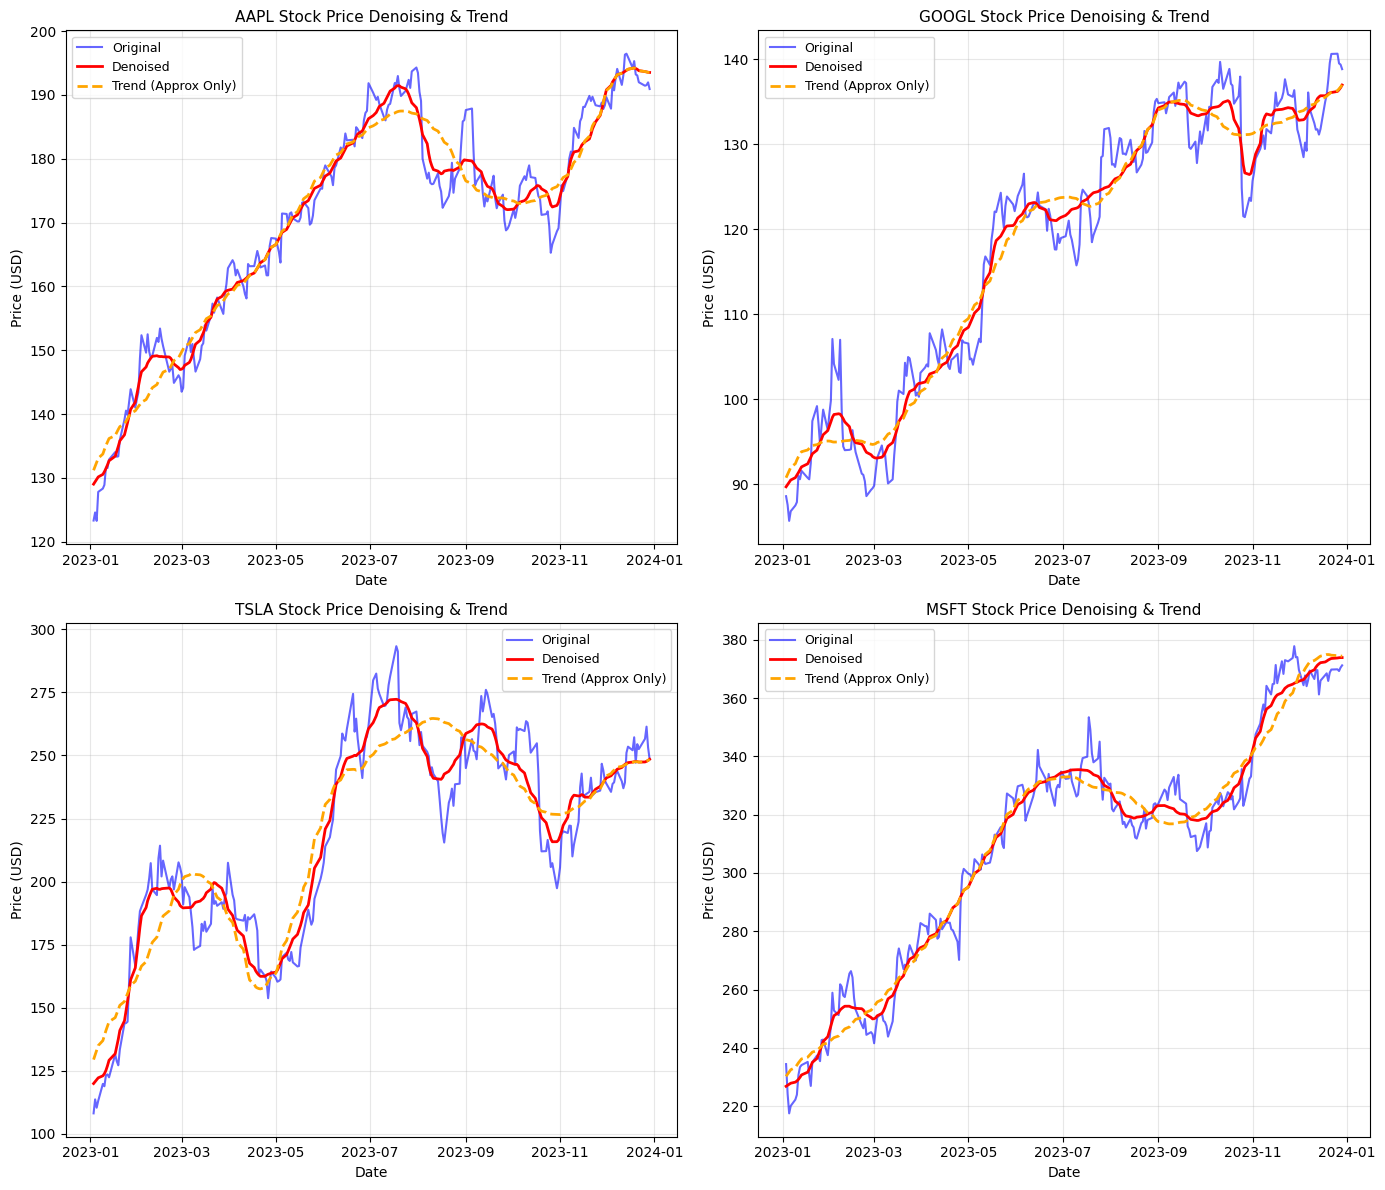

In [ ]:
import yfinance as yf
import pywt
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# ============================================================================
# CONFIGURATION PARAMETERS
# ============================================================================
SYMBOLS = ['AAPL', 'GOOGL', 'TSLA', 'MSFT']
START_DATE = '2023-01-01'
END_DATE = '2024-01-01'

WAVELET_TYPE = 'db4'              
DECOMP_LEVELS = 6                 
THRESHOLD_MODE = 'soft'           
NOISE_ESTIMATION_METHOD = 'bayes'  # 'bayes', 'sure', 'minimax', 'lastcoef', 'default'

FIGURE_SIZE = (14, 12)
DPI = 300
SAVE_PLOT = True
PLOT_FILENAME = 'stock_denoising_vs_trend.png'

# ============================================================================
# FUNCTIONS
# ============================================================================

def download_stock_data(symbols, start_date, end_date):
    """Download stock closing prices as pandas Series."""
    stock_data = {}
    for symbol in symbols:
        try:
            data = yf.download(symbol, start=start_date, end=end_date, progress=False)
            if not data.empty:
                stock_data[symbol] = data['Close']
                print(f"✅ {symbol}: {len(data)} points downloaded")
            else:
                print(f"⚠️ {symbol}: No data retrieved")
        except Exception as e:
            print(f"❌ {symbol}: {e}")
    return stock_data

def wavelet_denoise(signal, wavelet='db4', levels=2, threshold_mode='soft', noise_method='lastcoef'):
    """
    Wavelet denoising:
    Returns denoised signal and noise.
    """
    signal = np.array(signal).flatten()
    n = len(signal)
    max_level = pywt.dwt_max_level(n, wavelet)
    levels = min(levels, max_level)
    levels = max(levels, 1)

    coeffs = pywt.wavedec(signal, wavelet, level=levels)

    # Noise estimation
    sigma = np.median(np.abs(coeffs[-1])) / 0.6745
    sigma = max(sigma, 1e-6)

    if noise_method.lower() == 'sure':
        threshold = sigma * np.sqrt(2 * np.log(n))
    elif noise_method.lower() == 'bayes':
        threshold = sigma * np.sqrt(2 * np.log(n) * np.log2(n))
    elif noise_method.lower() == 'minimax':
        threshold = sigma * (0.3936 + 0.1829 * np.log2(n)) if n > 32 else sigma * np.sqrt(2 * np.log(n))
    else:
        threshold = sigma * np.sqrt(2 * np.log(n))

    # Threshold all details
    denoised_coeffs = [coeffs[0]] + [pywt.threshold(c, threshold, mode=threshold_mode) for c in coeffs[1:]]
    reconstructed = pywt.waverec(denoised_coeffs, wavelet)[:n]
    noise = signal - reconstructed

    return reconstructed, noise, threshold

def wavelet_trend(signal, wavelet='db4', levels=2):
    """Return the pure approximation trend (last-level approximation only)."""
    signal = np.array(signal).flatten()
    n = len(signal)
    max_level = pywt.dwt_max_level(n, wavelet)
    levels = min(levels, max_level)
    levels = max(levels, 1)

    coeffs = pywt.wavedec(signal, wavelet, level=levels)
    # zero all details
    trend_coeffs = [coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]]
    trend = pywt.waverec(trend_coeffs, wavelet)[:n]
    return trend

# ============================================================================
# MAIN SCRIPT
# ============================================================================

stock_data = download_stock_data(SYMBOLS, START_DATE, END_DATE)

if not stock_data:
    print("⚠️ No stock data downloaded.")
    exit()

fig, axes = plt.subplots(2, 2, figsize=FIGURE_SIZE)
axes = axes.flatten()

for i, (symbol, series) in enumerate(stock_data.items()):
    if i >= 4:
        break
    prices = series.values
    dates = series.index

    # Denoised signal
    denoised, noise, threshold = wavelet_denoise(prices, wavelet=WAVELET_TYPE,
                                                 levels=DECOMP_LEVELS,
                                                 threshold_mode=THRESHOLD_MODE,
                                                 noise_method=NOISE_ESTIMATION_METHOD)
    # Approximation trend
    trend = wavelet_trend(prices, wavelet=WAVELET_TYPE, levels=DECOMP_LEVELS)

    axes[i].plot(dates, prices, label='Original', alpha=0.6, color='blue')
    axes[i].plot(dates, denoised, label='Denoised', linewidth=2, color='red')
    axes[i].plot(dates, trend, label='Trend (Approx Only)', linewidth=2, linestyle='--', color='orange')
    axes[i].set_title(f'{symbol} Stock Price Denoising & Trend', fontsize=11)
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('Price (USD)')
    axes[i].grid(True, alpha=0.3)
    axes[i].legend(fontsize=9)

plt.tight_layout()
if SAVE_PLOT:
    plt.savefig(f"./output/3.1_{PLOT_FILENAME}", dpi=DPI, bbox_inches='tight')
    print(f"📁 Saved plot as 3.1_{PLOT_FILENAME}")
plt.show()

### 3.4.1 Advanced Stock Analysis: Volatility Extraction

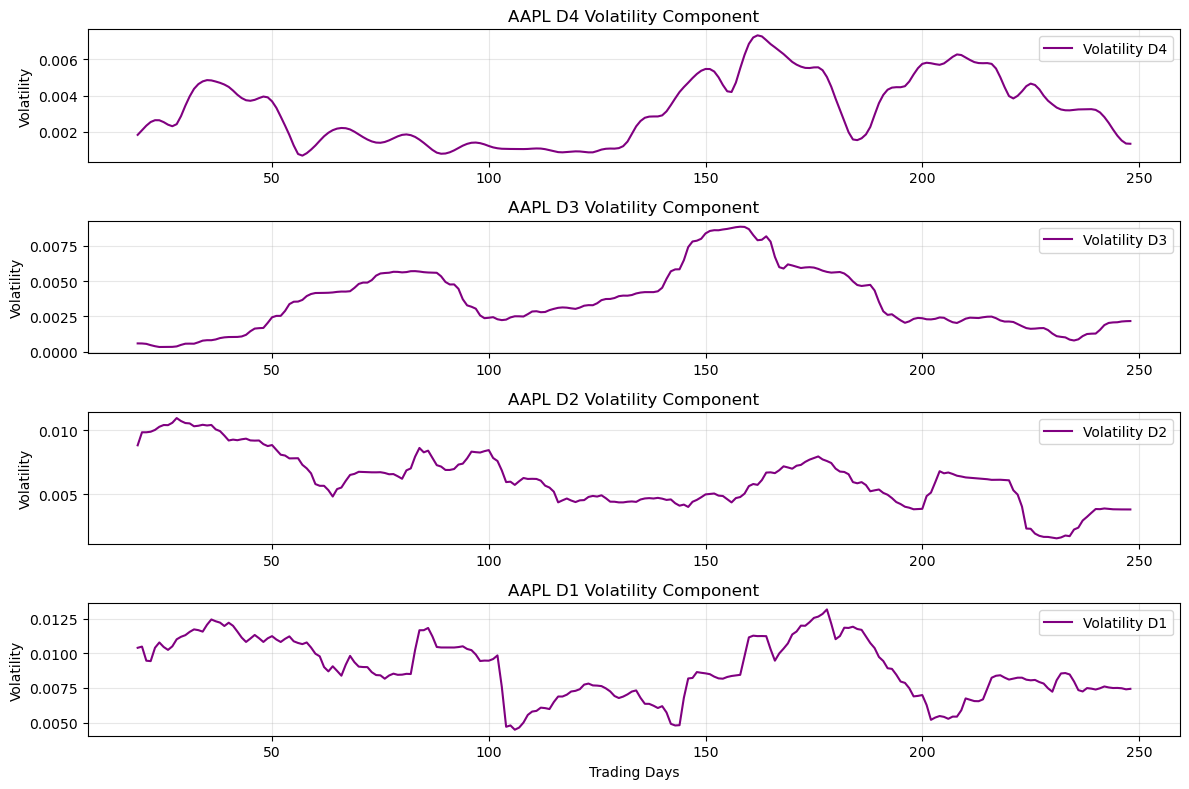

In [ ]:
def extract_volatility_components(prices, window=20, wavelet='db4', levels=4):
    """Extract volatility components using wavelet decomposition of log returns."""
    # Ensure numpy array and drop NaN/zeros
    prices = np.array(prices, dtype=float)
    prices = prices[~np.isnan(prices)]
    prices = prices[prices > 0]

    # Calculate log returns
    returns = np.diff(np.log(prices))
    if len(returns) == 0:
        raise ValueError("Not enough valid data to compute returns.")

    # Adjust levels safely
    max_level = pywt.dwt_max_level(len(returns), wavelet)
    levels = min(levels, max_level)
    if levels < 1:
        raise ValueError("Signal too short for wavelet decomposition.")

    # Apply DWT to returns
    coeffs = pywt.wavedec(returns, wavelet, level=levels)

    # Reconstruct individual detail components
    components = {}
    for i in range(1, len(coeffs)):
        temp_coeffs = [np.zeros_like(c) for c in coeffs]
        temp_coeffs[i] = coeffs[i]
        comp = pywt.waverec(temp_coeffs, wavelet)
        components[f'D{len(coeffs)-i}'] = comp[:len(returns)]

    # Rolling volatility of each component
    volatility_components = {}
    for name, comp in components.items():
        vol = pd.Series(comp).rolling(window=window).std()
        volatility_components[name] = vol

    return volatility_components

if 'AAPL' in stock_data:
    vol_components = extract_volatility_components(stock_data['AAPL'], window=20)

    plt.figure(figsize=(12, 8))
    for i, (name, vol) in enumerate(vol_components.items()):
        plt.subplot(len(vol_components), 1, i+1)
        plt.plot(vol.values, label=f'Volatility {name}', color='purple')
        plt.title(f'AAPL {name} Volatility Component')
        plt.ylabel('Volatility')
        plt.grid(True, alpha=0.3)
        plt.legend()

    plt.xlabel('Trading Days')
    plt.tight_layout()
    plt.savefig('./output/aapl_volatility_components.png', dpi=300, bbox_inches='tight')
    plt.show()



## 3.5 Environmental Data Analysis Across Global Cities

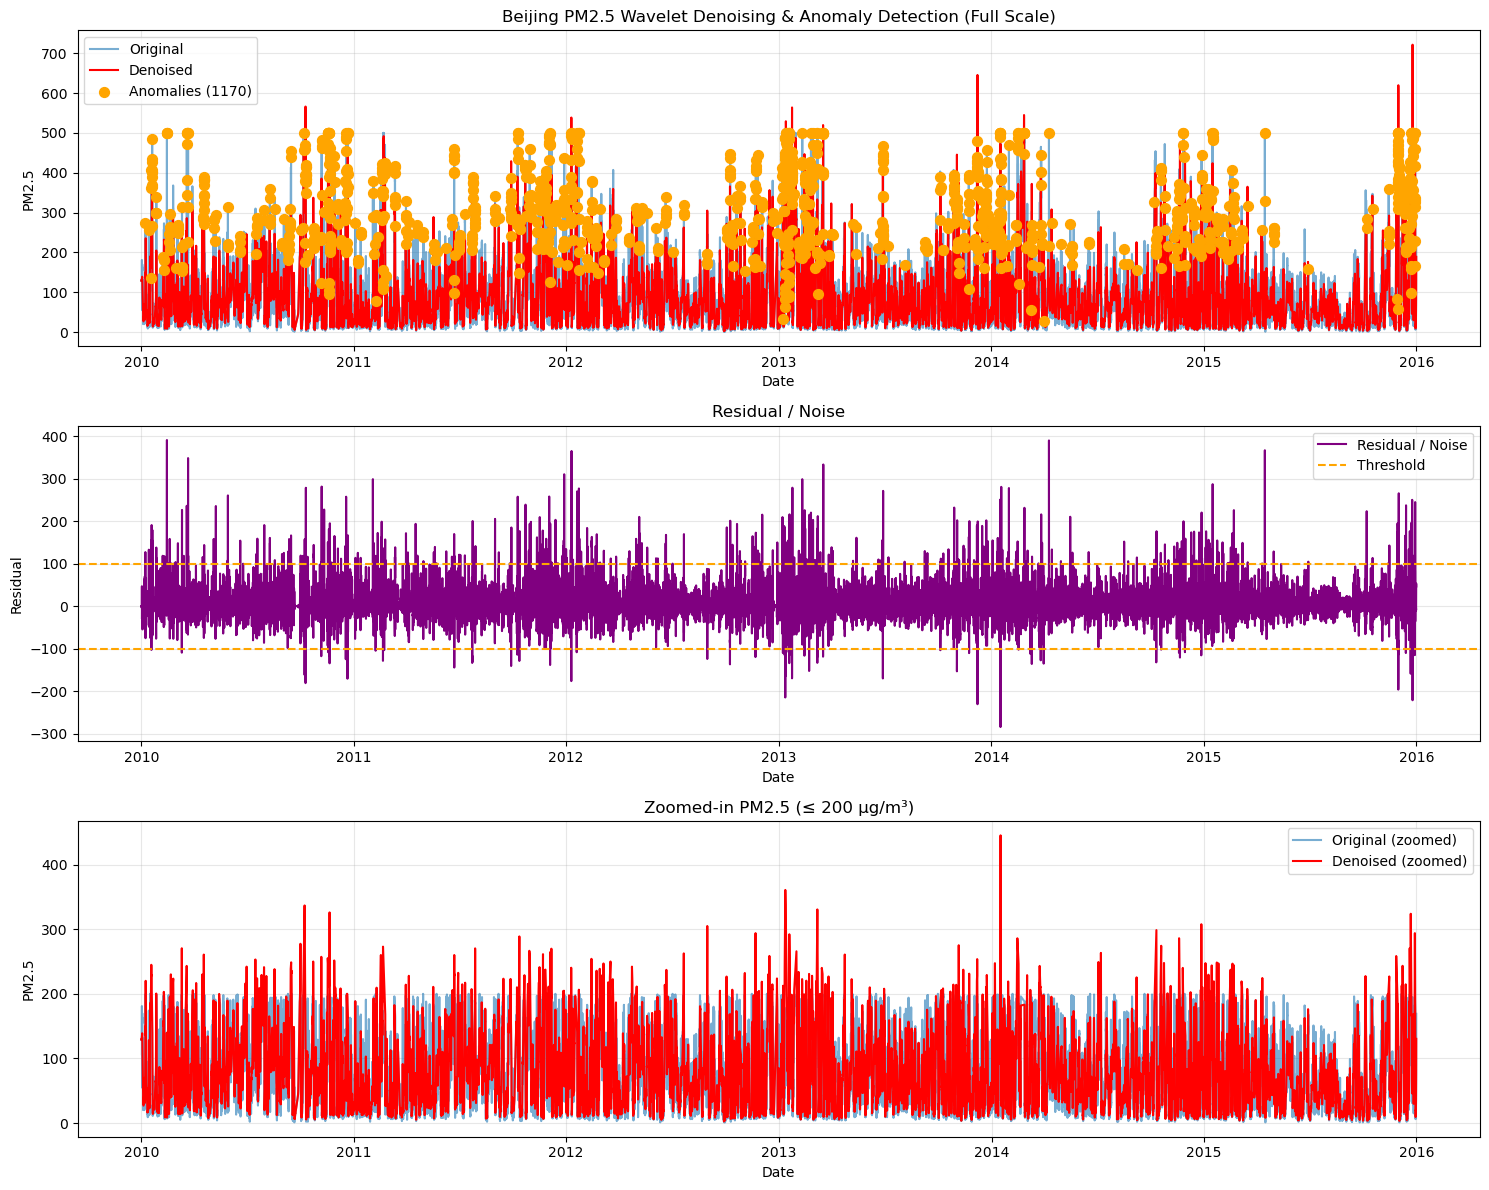

Beijing: Plot saved, anomalies detected: 1170


In [ ]:
import os
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt

# ===============================
# CONFIGURATION
# ===============================
file_path = './data/BeijingPM20100101_20151231.csv'  # Beijing PM2.5 CSV
pm_column = 'PM_US Post'      # PM column for analysis
wavelet_type = 'db4'
decomp_levels = 4
threshold_mode = 'soft'
anomaly_multiplier = 3.0
max_pm_clip = 500             # max PM2.5 value for clipping
zoom_pm_max = 200             # max value for zoomed-in plot

# ===============================
# FUNCTIONS
# ===============================
def wavelet_denoise(signal, wavelet=wavelet_type, levels=decomp_levels, threshold_mode=threshold_mode):
    """Wavelet denoising of a signal"""
    signal = np.array(signal).flatten()
    n = len(signal)
    max_level = pywt.dwt_max_level(n, wavelet)
    levels = min(levels, max_level)

    coeffs = pywt.wavedec(signal, wavelet, level=levels)
    sigma = np.median([np.median(np.abs(c)) for c in coeffs[1:]]) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(n))

    denoised_coeffs = [coeffs[0]]
    for i in range(1, len(coeffs)):
        denoised_coeffs.append(pywt.threshold(coeffs[i], threshold, mode=threshold_mode))

    reconstructed = pywt.waverec(denoised_coeffs, wavelet)
    reconstructed = reconstructed[:n]
    return reconstructed, coeffs

def detect_anomalies(signal, denoised_signal, multiplier=anomaly_multiplier):
    """Detect anomalies based on residuals"""
    residual = signal - denoised_signal
    threshold = multiplier * np.std(residual)
    anomaly_indices = np.where(np.abs(residual) > threshold)[0]
    return anomaly_indices

# ===============================
# PROCESS BEIJING DATA
# ===============================
try:
    df = pd.read_csv(file_path)
    df['datetime'] = pd.to_datetime(df[['year','month','day','hour']])

    # Extract PM values and handle missing data
    pm_values = df[pm_column].interpolate().fillna(method='bfill').values
    pm_values = np.clip(pm_values, 0, max_pm_clip)
    dates = df['datetime']

    # Apply log-transform wavelet denoising
    pm_log = np.log1p(pm_values)
    denoised_log, coeffs = wavelet_denoise(pm_log)
    denoised_values = np.expm1(denoised_log)

    # Detect anomalies
    anomalies = detect_anomalies(pm_values, denoised_values)

    # ===============================
    # Plot results
    # ===============================
    plt.figure(figsize=(15,12))

    # Top: original vs denoised (full scale)
    plt.subplot(3,1,1)
    plt.plot(dates, pm_values, label='Original', alpha=0.6)
    plt.plot(dates, denoised_values, label='Denoised', color='red')
    if len(anomalies) > 0:
        plt.scatter(dates[anomalies], pm_values[anomalies], color='orange',
                    s=50, label=f'Anomalies ({len(anomalies)})', zorder=5)
    plt.title('Beijing PM2.5 Wavelet Denoising & Anomaly Detection (Full Scale)')
    plt.xlabel('Date')
    plt.ylabel('PM2.5')
    plt.legend()
    plt.grid(alpha=0.3)

    # Middle: residual / noise
    plt.subplot(3,1,2)
    residual = pm_values - denoised_values
    plt.plot(dates, residual, label='Residual / Noise', color='purple')
    plt.axhline(y=anomaly_multiplier*np.std(residual), color='orange', linestyle='--', label='Threshold')
    plt.axhline(y=-anomaly_multiplier*np.std(residual), color='orange', linestyle='--')
    plt.title('Residual / Noise')
    plt.xlabel('Date')
    plt.ylabel('Residual')
    plt.legend()
    plt.grid(alpha=0.3)

    # Bottom: zoomed-in view
    plt.subplot(3,1,3)
    zoom_idx = pm_values <= zoom_pm_max
    plt.plot(dates[zoom_idx], pm_values[zoom_idx], label='Original (zoomed)', alpha=0.6)
    plt.plot(dates[zoom_idx], denoised_values[zoom_idx], label='Denoised (zoomed)', color='red')
    plt.title(f'Zoomed-in PM2.5 (≤ {zoom_pm_max} μg/m³)')
    plt.xlabel('Date')
    plt.ylabel('PM2.5')
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()

    # Save figure
    output_file = './output/output/Beijing_pm25_wavelet.png'
    os.makedirs('./output', exist_ok=True)
    plt.savefig(output_file, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"Beijing: Plot saved, anomalies detected: {len(anomalies)}")

except Exception as e:
    print(f"Failed to process Beijing data: {e}")


### 3.5.1 Seasonal Pattern Analysis

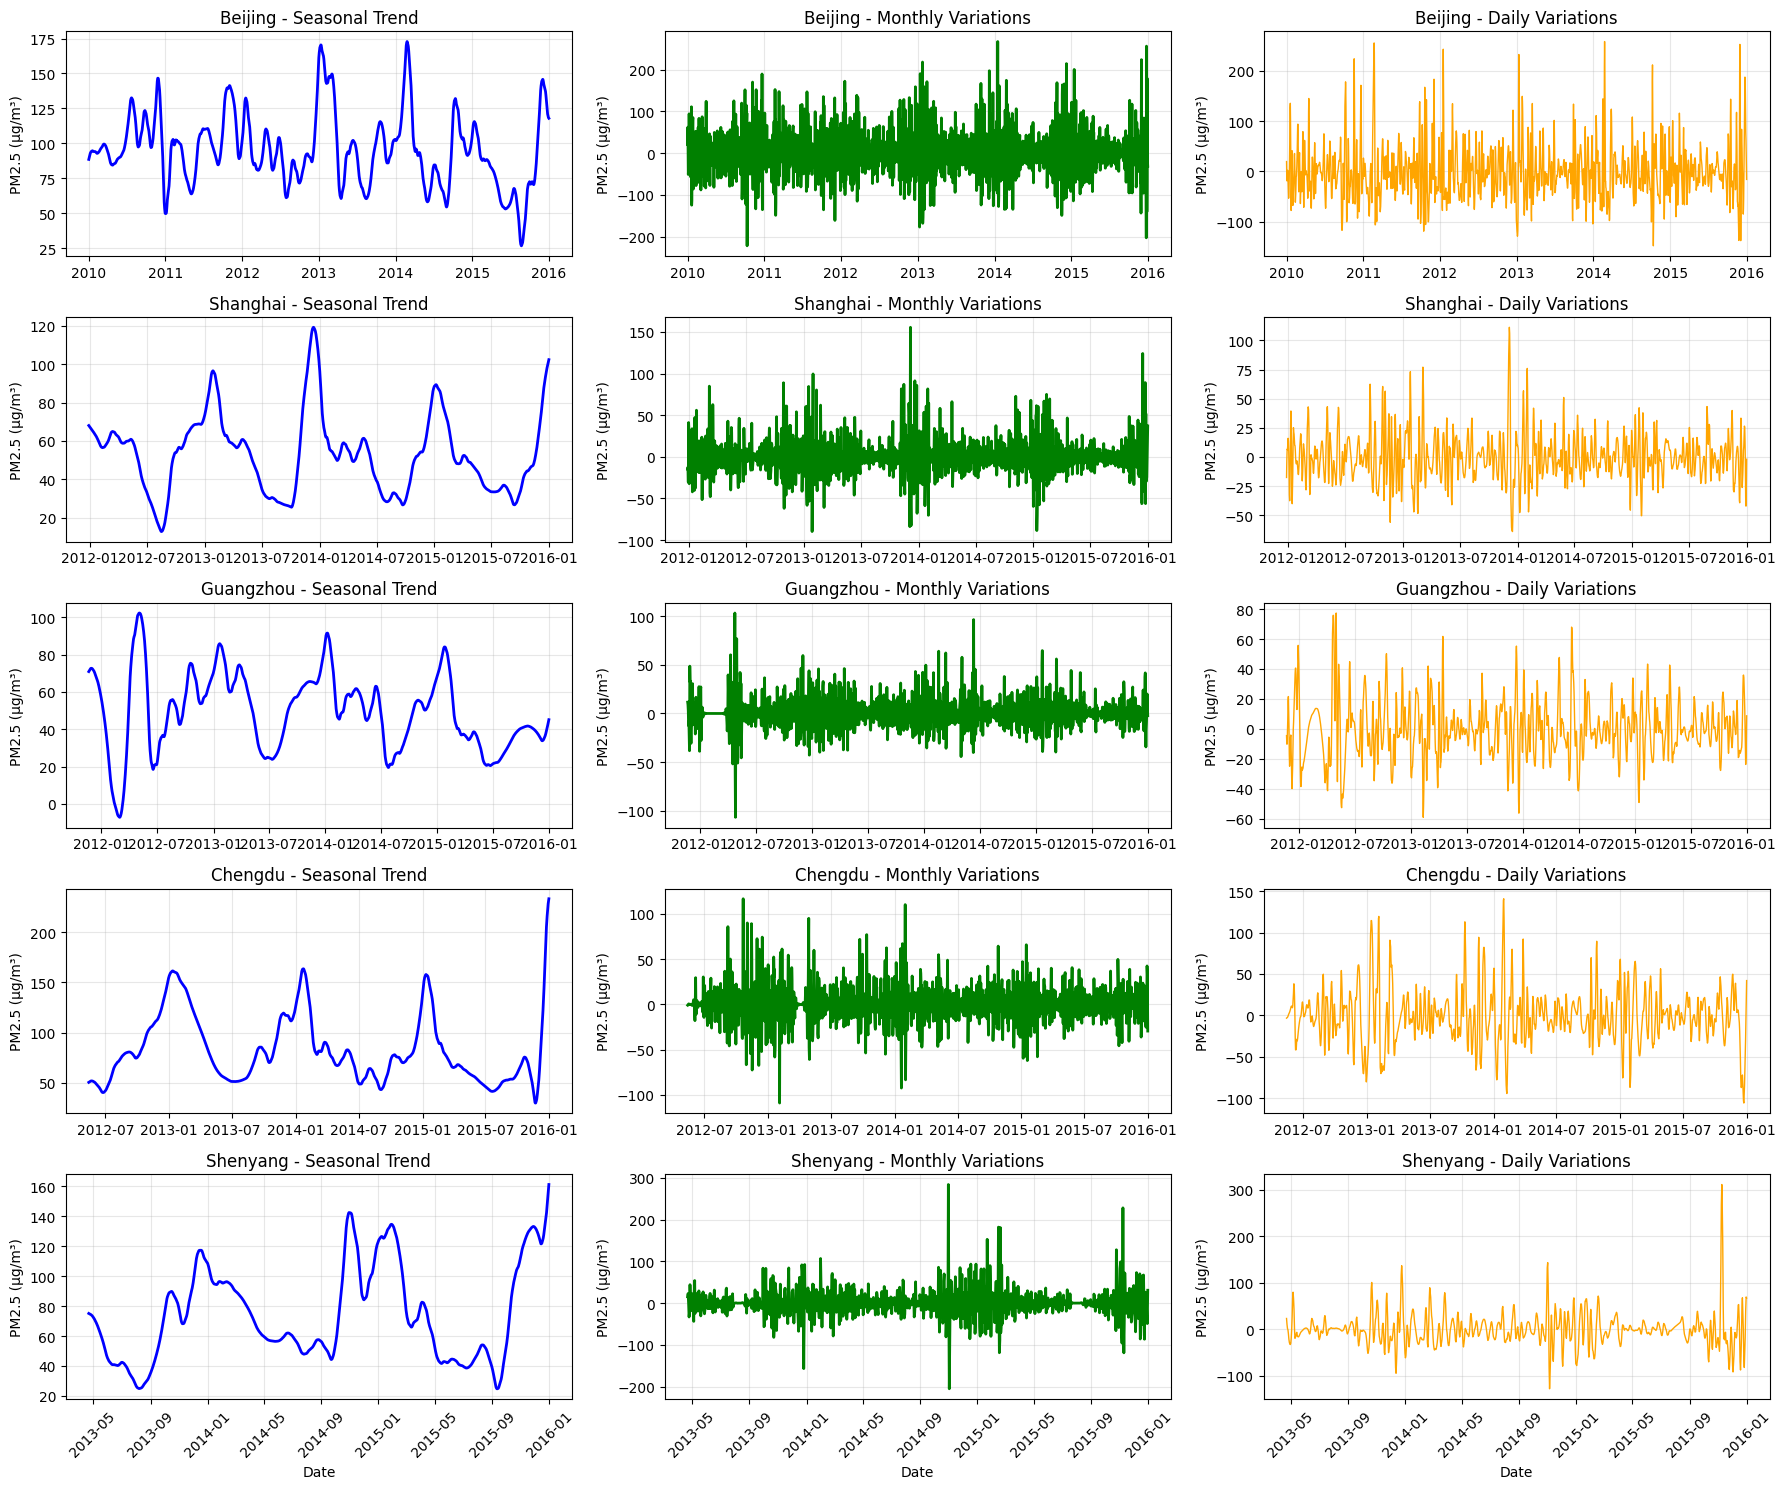

In [ ]:
import os
import pandas as pd
import numpy as np
import pywt
import matplotlib.pyplot as plt

# =============================================================================
# LOAD DATA FOR ALL CITIES
# =============================================================================
data_dir = "./data/chinapm"
city_files = {
    "Beijing": "BeijingPM20100101_20151231.csv",
    "Shanghai": "ShanghaiPM20100101_20151231.csv",
    "Guangzhou": "GuangzhouPM20100101_20151231.csv",
    "Chengdu": "ChengduPM20100101_20151231.csv",
    "Shenyang": "ShenyangPM20100101_20151231.csv"
}

environmental_data = {}

for city, filename in city_files.items():
    filepath = os.path.join(data_dir, filename)
    df = pd.read_csv(filepath)

    # Build datetime column
    df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])

    # Use "PM_US Post" column as PM2.5 concentration (common across datasets)
    df = df.dropna(subset=["PM_US Post"])

    environmental_data[city] = {
        "dates": df["datetime"].tolist(),
        "values": df["PM_US Post"].tolist()
    }

# =============================================================================
# WAVELET SEASONAL ANALYSIS
# =============================================================================
def seasonal_wavelet_analysis(city_data):
    """Perform seasonal decomposition using wavelets."""
    seasonal_results = {}
    
    for city, data in city_data.items():
        values = data['values']
        dates = pd.to_datetime(data['dates'])
        
        if len(values) < 100:
            continue
            
        # Create time series with proper frequency
        ts = pd.Series(values, index=dates)
        ts = ts.resample('D').mean().interpolate()  # Daily averages
        
        # Apply 5-level DWT for seasonal analysis
        coeffs = pywt.wavedec(ts.values, 'db4', level=5)
        
        # Reconstruct different temporal components
        # A5: Very long-term trends (seasonal)
        seasonal_coeffs = [coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]]
        seasonal = pywt.waverec(seasonal_coeffs, 'db4')
        
        # D4-D5: Monthly to seasonal variations
        monthly_coeffs = [np.zeros_like(coeffs[0])] + [np.zeros_like(c) for c in coeffs[1:-2]] + coeffs[-2:]
        monthly = pywt.waverec(monthly_coeffs, 'db4')
        
        # D1-D3: Daily to weekly variations
        daily_coeffs = [np.zeros_like(coeffs[0])] + coeffs[1:-2] + [np.zeros_like(c) for c in coeffs[-2:]]
        daily = pywt.waverec(daily_coeffs, 'db4')
        
        # Ensure all components have the same length
        min_len = min(len(seasonal), len(monthly), len(daily), len(ts))
        seasonal_results[city] = {
            'dates': ts.index[:min_len],
            'original': ts.values[:min_len],
            'seasonal': seasonal[:min_len],
            'monthly': monthly[:min_len],
            'daily': daily[:min_len]
        }
    
    return seasonal_results

# Perform seasonal analysis
seasonal_analysis = seasonal_wavelet_analysis(environmental_data)

# =============================================================================
# VISUALIZATION
# =============================================================================
selected_cities = list(seasonal_analysis.keys())  # all 5 cities

fig, axes = plt.subplots(len(selected_cities), 3, figsize=(18, 15))

for i, city in enumerate(selected_cities):
    data = seasonal_analysis[city]
    dates = data['dates']
    
    # Seasonal component
    axes[i, 0].plot(dates, data['seasonal'], color='blue', linewidth=2)
    axes[i, 0].set_title(f'{city} - Seasonal Trend')
    axes[i, 0].set_ylabel('PM2.5 (μg/m³)')
    axes[i, 0].grid(True, alpha=0.3)
    
    # Monthly variations
    axes[i, 1].plot(dates, data['monthly'], color='green', linewidth=2)
    axes[i, 1].set_title(f'{city} - Monthly Variations')
    axes[i, 1].set_ylabel('PM2.5 (μg/m³)')
    axes[i, 1].grid(True, alpha=0.3)
    
    # Daily variations
    axes[i, 2].plot(dates, data['daily'], color='orange', linewidth=1)
    axes[i, 2].set_title(f'{city} - Daily Variations')
    axes[i, 2].set_ylabel('PM2.5 (μg/m³)')
    axes[i, 2].grid(True, alpha=0.3)
    
    if i == len(selected_cities) - 1:  # last row
        for j in range(3):
            axes[i, j].set_xlabel('Date')
            axes[i, j].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig("./output/seasonal_wavelet_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


## 3.6 Multiscale Anomaly Detection
### 3.6.1 Advanced Anomaly Detection Methodology

In [6]:
import numpy as np
import pywt
import pandas as pd
import matplotlib.pyplot as plt

def advanced_anomaly_detection(signal, wavelet='db4', levels=4, methods=['statistical', 'adaptive']):
    """
    Advanced anomaly detection using multiple methods and scales.
    
    Parameters:
    - signal: Input time series
    - wavelet: Wavelet type
    - levels: Decomposition levels
    - methods: List of detection methods to apply
    """
    # Decompose signal
    coeffs = pywt.wavedec(signal, wavelet, level=levels)
    
    anomalies = {}
    
    for level in range(1, min(len(coeffs), 4)):  # Analyze detail coefficients
        detail_coeffs = coeffs[level]
        level_anomalies = {}
        
        # Statistical method (traditional threshold)
        if 'statistical' in methods:
            threshold = 2.5 * np.std(detail_coeffs)
            stat_anomalies = np.where(np.abs(detail_coeffs) > threshold)[0]
            level_anomalies['statistical'] = stat_anomalies
        
        # Adaptive threshold method
        if 'adaptive' in methods:
            # Use median absolute deviation for robust threshold
            mad = np.median(np.abs(detail_coeffs - np.median(detail_coeffs)))
            adaptive_threshold = 3 * mad / 0.6745  # Convert to standard deviation
            adaptive_anomalies = np.where(np.abs(detail_coeffs) > adaptive_threshold)[0]
            level_anomalies['adaptive'] = adaptive_anomalies
        
        # Percentile-based method
        if 'percentile' in methods:
            upper_percentile = np.percentile(np.abs(detail_coeffs), 95)
            percentile_anomalies = np.where(np.abs(detail_coeffs) > upper_percentile)[0]
            level_anomalies['percentile'] = percentile_anomalies
        
        anomalies[f'D{levels-level+1}'] = level_anomalies
    
    return anomalies, coeffs

def plot_multiscale_anomalies(signal, dates, anomalies, title="Multiscale Anomaly Detection"):
    """Plot anomalies detected at different scales."""
    # Ensure arrays
    signal = np.array(signal)
    dates = np.array(dates)

    fig, axes = plt.subplots(len(anomalies) + 1, 1, figsize=(15, 12))
    
    # Plot original signal
    axes[0].plot(dates, signal, 'b-', linewidth=1, alpha=0.7, label='Original Signal')
    axes[0].set_title(f'{title} - Original Signal')
    axes[0].set_ylabel('Value')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()
    
    # Plot anomalies for each scale
    colors = ['red', 'orange', 'green', 'purple']
    
    for i, (scale, methods) in enumerate(anomalies.items()):
        axes[i+1].plot(dates, signal, 'b-', linewidth=1, alpha=0.3, label='Signal')
        
        for j, (method, indices) in enumerate(methods.items()):
            if len(indices) > 0:
                valid_indices = indices[indices < len(signal)]
                if len(valid_indices) > 0:
                    axes[i+1].scatter(dates[valid_indices], signal[valid_indices], 
                                    c=colors[j % len(colors)], s=50, 
                                    marker='o', label=f'{method} ({len(valid_indices)})',
                                    zorder=5)
        
        axes[i+1].set_title(f'Scale {scale} Anomalies')
        axes[i+1].set_ylabel('Value')
        axes[i+1].grid(True, alpha=0.3)
        axes[i+1].legend()
        
        if i == len(anomalies) - 1:  # Last subplot
            axes[i+1].set_xlabel('Date')
            axes[i+1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    return fig



### 3.6.2 Stock Market Shock Detection

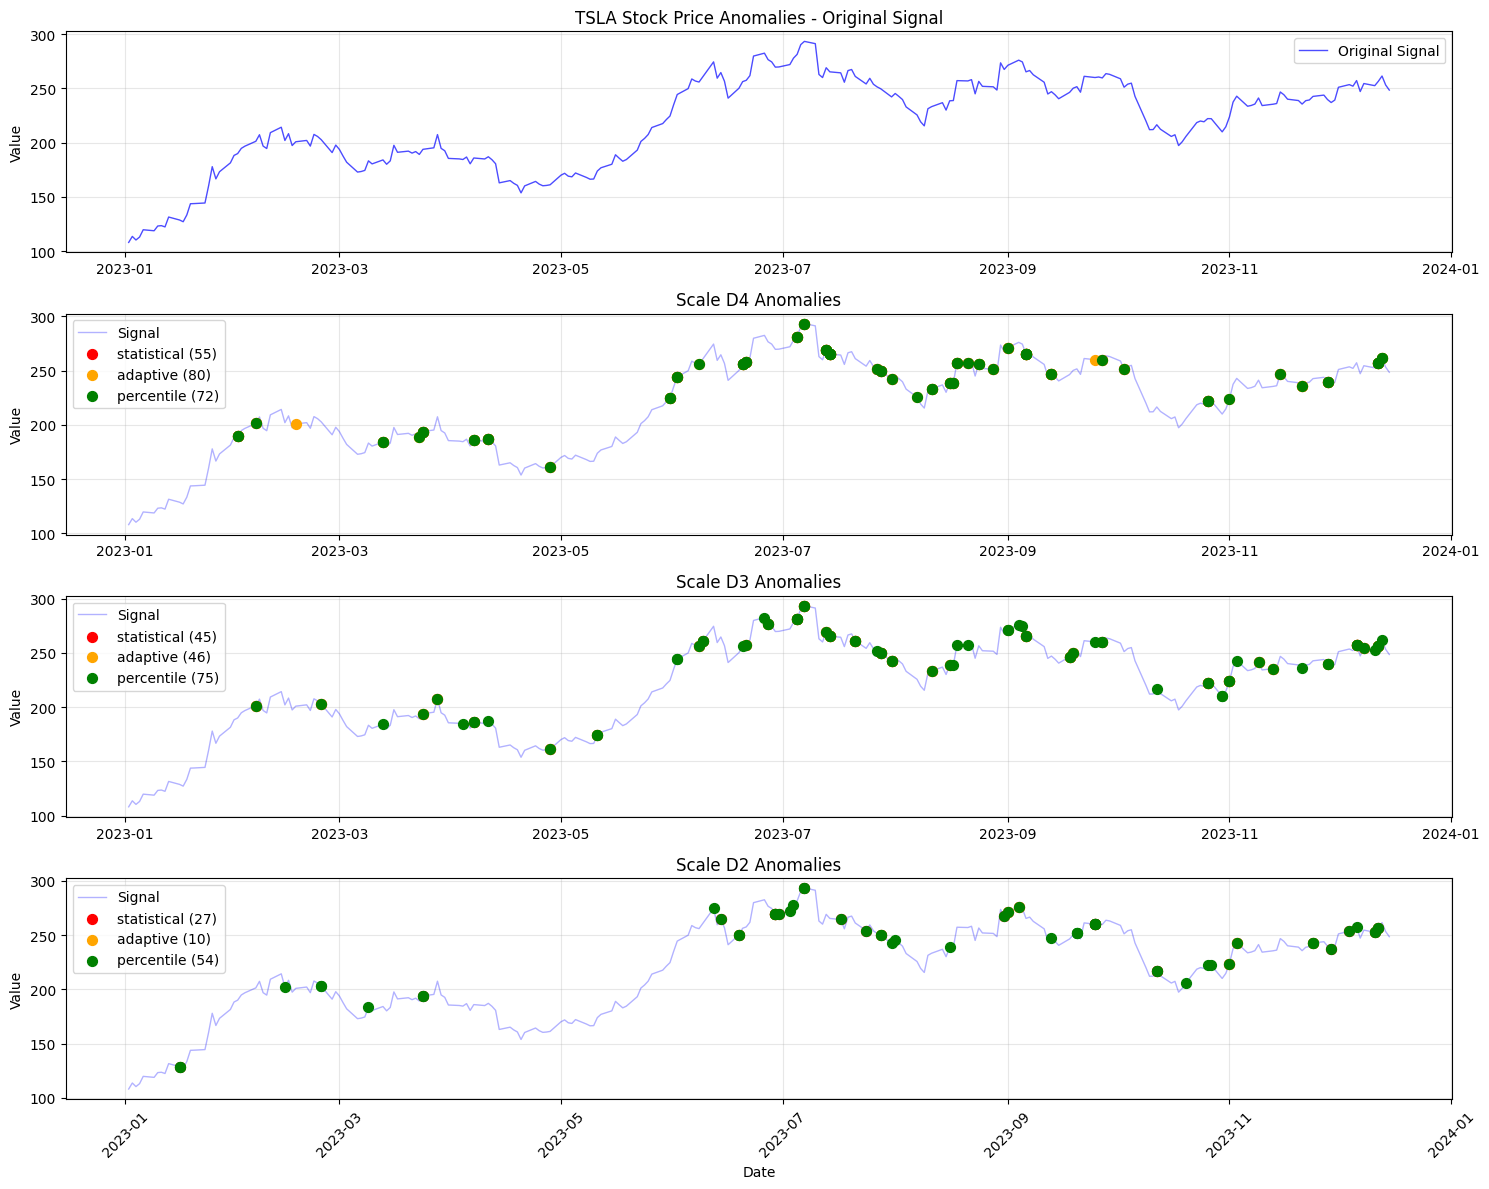


TSLA Anomaly Detection Summary:
  D4:
    statistical: 55 anomalies
    adaptive: 80 anomalies
    percentile: 72 anomalies
  D3:
    statistical: 45 anomalies
    adaptive: 46 anomalies
    percentile: 75 anomalies
  D2:
    statistical: 27 anomalies
    adaptive: 10 anomalies
    percentile: 54 anomalies


In [ ]:
# Apply advanced anomaly detection to stock data
if stock_data:
    # Select a volatile stock for demonstration
    symbol = 'TSLA'  # Tesla is known for volatility
    if symbol in stock_data:
        prices = stock_data[symbol]
        dates = pd.date_range(start=START_DATE, end=END_DATE, freq='B')[:len(prices)]
        
        # Detect anomalies
        anomalies, coeffs = advanced_anomaly_detection(
            prices, 
            wavelet='db4', 
            levels=4, 
            methods=['statistical', 'adaptive', 'percentile']
        )
        
        # Plot results
        fig = plot_multiscale_anomalies(prices, dates, anomalies, 
                                      title=f"{symbol} Stock Price Anomalies")
        plt.savefig(f'./output/3.5_{symbol}_multiscale_anomalies.png', dpi=300, bbox_inches='tight')
        plt.show()
        
        # Print anomaly summary
        print(f"\n{symbol} Anomaly Detection Summary:")
        for scale, methods in anomalies.items():
            print(f"  {scale}:")
            for method, indices in methods.items():
                print(f"    {method}: {len(indices)} anomalies")

### 3.6.3 Environmental Spike Detection with Context


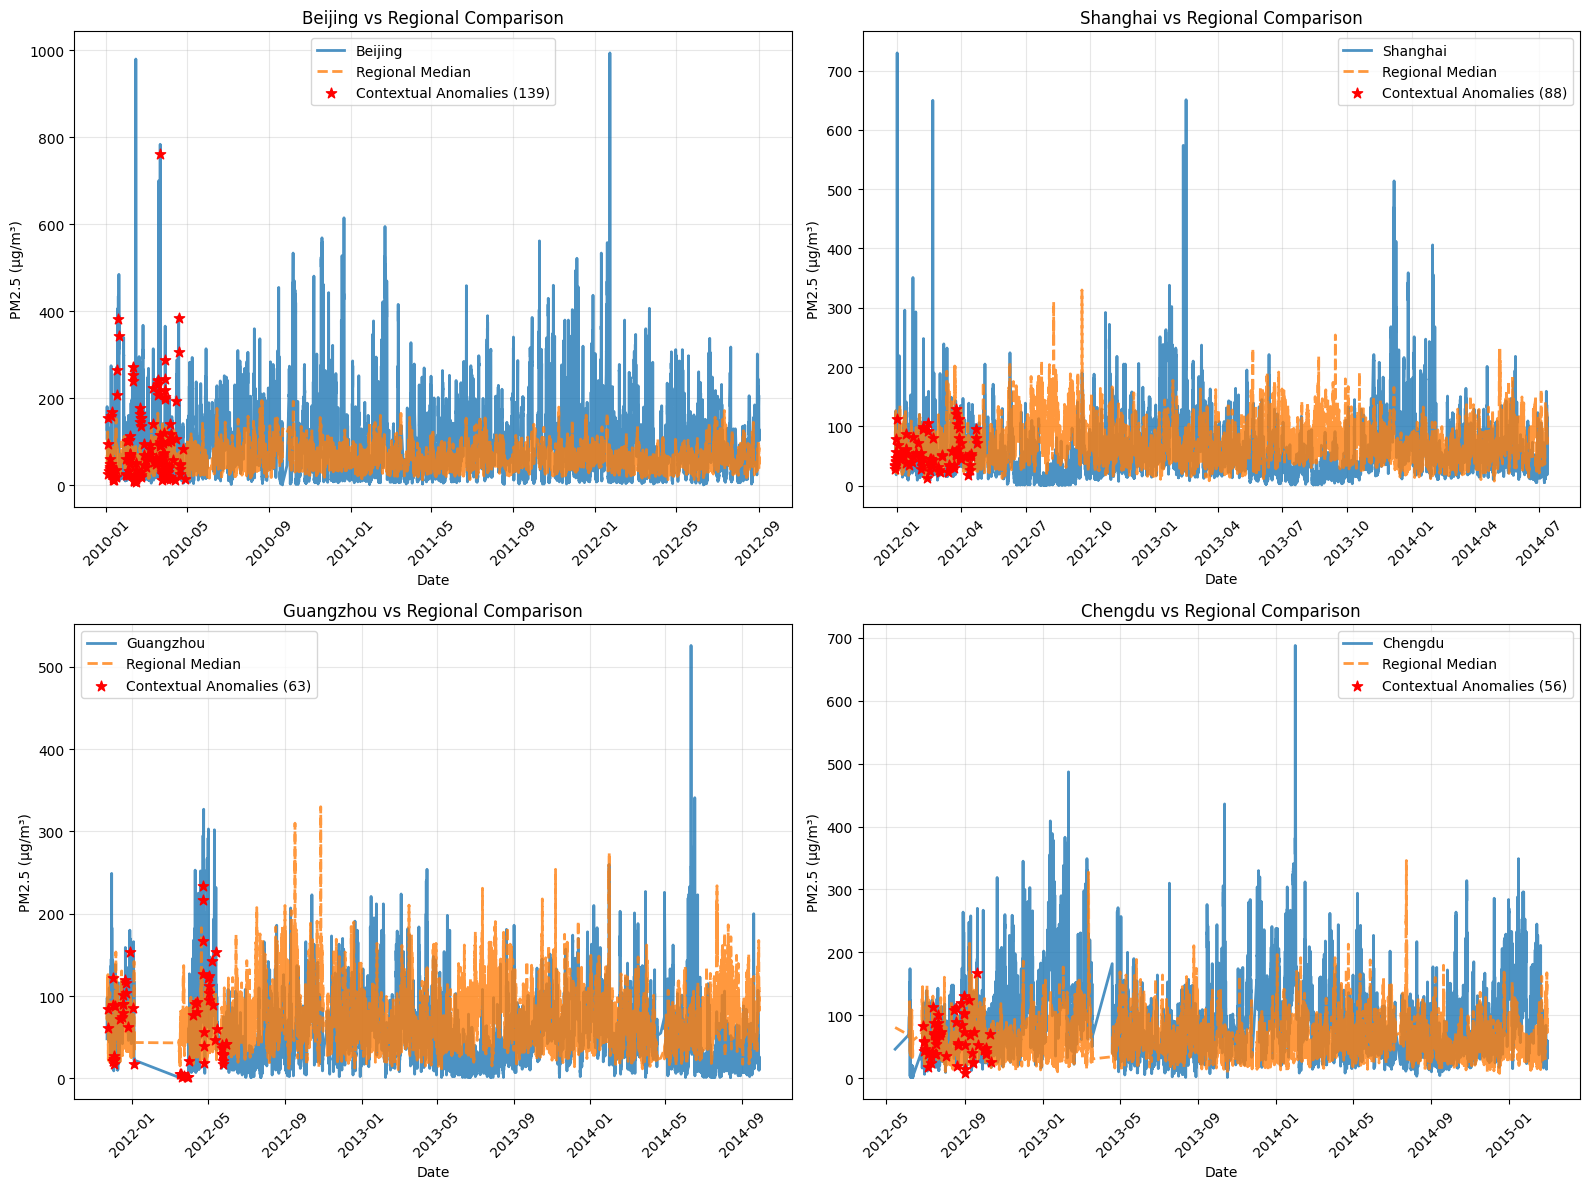


Contextual Anomaly Analysis Summary:

Beijing:
  Contextual anomalies detected: 139
  Average PM2.5: 99.25 μg/m³
  Regional median: 60.24 μg/m³
  Relative pollution level: +64.8%
  Compared to: Shanghai, Guangzhou, Chengdu, Shenyang

Shanghai:
  Contextual anomalies detected: 88
  Average PM2.5: 55.49 μg/m³
  Regional median: 69.40 μg/m³
  Relative pollution level: -20.0%
  Compared to: Beijing, Guangzhou, Chengdu, Shenyang

Guangzhou:
  Contextual anomalies detected: 63
  Average PM2.5: 54.80 μg/m³
  Regional median: 69.66 μg/m³
  Relative pollution level: -21.3%
  Compared to: Beijing, Shanghai, Chengdu, Shenyang

Chengdu:
  Contextual anomalies detected: 56
  Average PM2.5: 90.18 μg/m³
  Regional median: 59.90 μg/m³
  Relative pollution level: +50.5%
  Compared to: Beijing, Shanghai, Guangzhou, Shenyang

Shenyang:
  Contextual anomalies detected: 91
  Average PM2.5: 75.84 μg/m³
  Regional median: 64.15 μg/m³
  Relative pollution level: +18.2%
  Compared to: Beijing, Shanghai, Guang

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

def contextual_anomaly_analysis(city_data, reference_cities=None):
    """Perform contextual anomaly analysis comparing cities."""
    if reference_cities is None:
        reference_cities = list(city_data.keys())
    
    contextual_results = {}
    
    for target_city in city_data.keys():
        if target_city not in reference_cities:
            continue
            
        target_values = city_data[target_city]['values']
        target_dates = city_data[target_city]['dates']
        
        # Other cities for comparison
        other_cities = [city for city in reference_cities if city != target_city]
        if len(other_cities) == 0:
            continue

        # Determine global minimum length across target + all reference cities
        min_len = min([len(target_values)] + [
            len(city_data[c]['values']) for c in other_cities if c in city_data
        ])
        if min_len == 0:
            continue

        # Adjust target values
        adjusted_target = target_values[:min_len]
        adjusted_dates = target_dates[:min_len]

        # Collect synchronized regional values
        regional_values = []
        for other_city in other_cities:
            if other_city in city_data:
                other_values = city_data[other_city]['values'][:min_len]
                regional_values.append(other_values)

        if not regional_values:
            continue

        # Convert to 2D array and compute regional median
        regional_matrix = np.vstack(regional_values)
        regional_median = np.median(regional_matrix, axis=0)

        # Calculate relative anomalies
        relative_diff = adjusted_target - regional_median

        # Detect contextual anomalies
        anomalies, coeffs = advanced_anomaly_detection(
            relative_diff, 
            wavelet='db4', 
            levels=3,
            methods=['adaptive']
        )
        
        contextual_results[target_city] = {
            'original': adjusted_target,
            'regional_median': regional_median,
            'relative_diff': relative_diff,
            'dates': adjusted_dates,
            'anomalies': anomalies,
            'other_cities': other_cities
        }
    
    return contextual_results

# Perform contextual analysis
contextual_analysis = contextual_anomaly_analysis(environmental_data)

# Visualize contextual anomalies for selected cities
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for i, (city, data) in enumerate(list(contextual_analysis.items())[:4]):
    # Plot original vs regional median
    axes[i].plot(data['dates'], data['original'], 
                label=f'{city}', linewidth=2, alpha=0.8)
    axes[i].plot(data['dates'], data['regional_median'], 
                label='Regional Median', linewidth=2, alpha=0.8, linestyle='--')
    
    # Mark contextual anomalies safely
    if 'D3' in data['anomalies'] and 'adaptive' in data['anomalies']['D3']:
        anomaly_indices = data['anomalies']['D3']['adaptive']
        if len(anomaly_indices) > 0:
            # Ensure NumPy array for fancy indexing
            anomaly_indices = np.array(anomaly_indices, dtype=int)
            anomaly_indices = anomaly_indices[anomaly_indices < len(data['original'])]

            if len(anomaly_indices) > 0:
                axes[i].scatter(np.array(data['dates'])[anomaly_indices], 
                                np.array(data['original'])[anomaly_indices],
                                color='red', s=60, marker='*', 
                                label=f'Contextual Anomalies ({len(anomaly_indices)})',
                                zorder=5)
    
    axes[i].set_title(f'{city} vs Regional Comparison')
    axes[i].set_xlabel('Date')
    axes[i].set_ylabel('PM2.5 (μg/m³)')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)
    axes[i].tick_params(axis='x', rotation=45)


plt.tight_layout()
plt.savefig('./output/contextual_anomaly_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# Print contextual analysis summary
print("\nContextual Anomaly Analysis Summary:")
for city, data in contextual_analysis.items():
    if 'D3' in data['anomalies'] and 'adaptive' in data['anomalies']['D3']:
        anomaly_count = len(data['anomalies']['D3']['adaptive'])
        mean_city = np.mean(data['original'])
        mean_regional = np.mean(data['regional_median'])
        relative_pollution = ((mean_city - mean_regional) / mean_regional) * 100
        
        print(f"\n{city}:")
        print(f"  Contextual anomalies detected: {anomaly_count}")
        print(f"  Average PM2.5: {mean_city:.2f} μg/m³")
        print(f"  Regional median: {mean_regional:.2f} μg/m³")
        print(f"  Relative pollution level: {relative_pollution:+.1f}%")
        print(f"  Compared to: {', '.join(data['other_cities'])}")


## 3.7 Comparison with Traditional Methods

### 3.7.1 Wavelets vs. Moving Averages

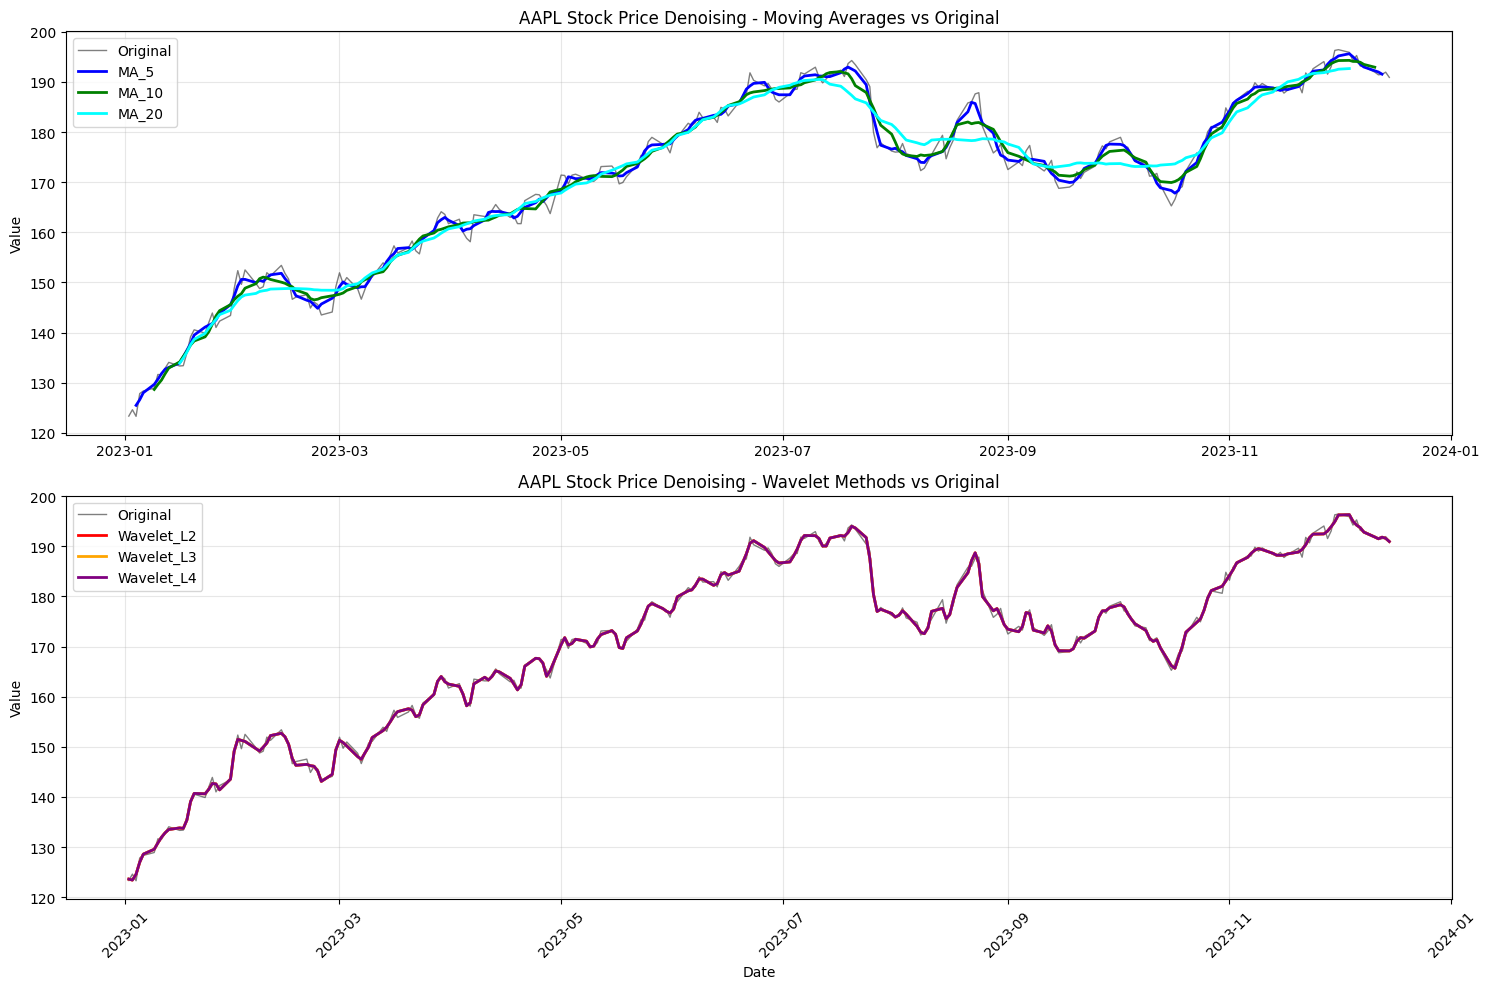


Performance Metrics Comparison:
Method          MSE          SNR (dB)     Trend Pres.  Edge Pres.  
--------------------------------------------------------------------------------
MA_5            6.10         17.11        0.990        0.458       
MA_10           15.42        13.24        0.977        0.325       
MA_20           36.12        9.79         0.949        0.187       
Wavelet_L2      0.55         27.40        0.999        0.787       
Wavelet_L3      0.55         27.40        0.999        0.787       
Wavelet_L4      0.55         27.40        0.999        0.787       


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt

def compare_methods(signal, dates, window_sizes=[5, 10, 20], wavelet_levels=[2, 3, 4]):
    """Compare wavelet denoising with moving averages."""
    # Ensure 1D
    signal = np.asarray(signal).flatten()
    
    results = {'original': signal, 'dates': dates}
    
    # Moving averages
    for window in window_sizes:
        ma = pd.Series(signal).rolling(window=window, center=True).mean().values
        results[f'MA_{window}'] = ma
    
    # Wavelet denoising
    for level in wavelet_levels:
        denoised, _, _ = wavelet_denoise(signal, levels=level)
        results[f'Wavelet_L{level}'] = denoised
    
    return results


def plot_method_comparison(results, title="Method Comparison"):
    """Plot comparison of different denoising methods."""
    fig, axes = plt.subplots(2, 1, figsize=(15, 10))
    
    # Plot all methods
    axes[0].plot(results['dates'], results['original'], 
                 label='Original', alpha=0.5, linewidth=1, color='black')
    
    # Moving averages
    ma_colors = ['blue', 'green', 'cyan']
    for i, key in enumerate([k for k in results.keys() if 'MA_' in k]):
        axes[0].plot(results['dates'], results[key], 
                     label=key, linewidth=2, color=ma_colors[i % len(ma_colors)])
    
    axes[0].set_title(f'{title} - Moving Averages vs Original')
    axes[0].set_ylabel('Value')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Wavelet methods
    axes[1].plot(results['dates'], results['original'], 
                 label='Original', alpha=0.5, linewidth=1, color='black')
    
    wavelet_colors = ['red', 'orange', 'purple']
    for i, key in enumerate([k for k in results.keys() if 'Wavelet_' in k]):
        axes[1].plot(results['dates'], results[key], 
                     label=key, linewidth=2, color=wavelet_colors[i % len(wavelet_colors)])
    
    axes[1].set_title(f'{title} - Wavelet Methods vs Original')
    axes[1].set_xlabel('Date')
    axes[1].set_ylabel('Value')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    return fig

def calculate_performance_metrics(original, denoised_methods):
    metrics = {}
    for method, denoised in denoised_methods.items():
        try:
            if isinstance(original, pd.DataFrame):
                orig_series = original.iloc[:, 0].dropna().reset_index(drop=True)
            else:
                orig_series = pd.Series(original).dropna().reset_index(drop=True)

            denoised_series = pd.Series(denoised).dropna().reset_index(drop=True)

            min_len = min(len(orig_series), len(denoised_series))
            orig_series = orig_series.iloc[:min_len]
            denoised_series = denoised_series.iloc[:min_len]

            # --- Metrics ---
            mse = np.mean((orig_series - denoised_series) ** 2)

            signal_power = np.var(orig_series)
            noise_power = np.var(orig_series - denoised_series)
            snr_original = 10 * np.log10(signal_power / np.var(orig_series - orig_series.mean()))
            snr_denoised = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else np.inf
            snr_improvement = snr_denoised - snr_original

            trend_corr = np.corrcoef(orig_series, denoised_series)[0, 1]
            edge_preservation = np.corrcoef(
                np.diff(orig_series), np.diff(denoised_series)
            )[0, 1]

            metrics[method] = {
                "MSE": mse,
                "SNR_improvement": snr_improvement,
                "Trend_preservation": trend_corr,
                "Edge_preservation": edge_preservation
            }
        except Exception as e:
            metrics[method] = {"Error": str(e)}

    return metrics



# Compare methods using stock data
if 'AAPL' in stock_data:
    prices = stock_data['AAPL']
    dates = pd.date_range(start=START_DATE, end=END_DATE, freq='B')[:len(prices)]
    
    # Compare different methods
    comparison_results = compare_methods(prices, dates)
    
    # Plot comparison
    fig = plot_method_comparison(comparison_results, title="AAPL Stock Price Denoising")
    plt.savefig('./output/method_comparison_aapl.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Calculate performance metrics
    denoised_methods = {k: v for k, v in comparison_results.items() 
                       if k not in ['original', 'dates']}
    metrics = calculate_performance_metrics(prices, denoised_methods)
    
    # Display metrics table
    metrics_df = pd.DataFrame(metrics).T
    print("\nPerformance Metrics Comparison:")
    print("="*80)
    print(f"{'Method':<15} {'MSE':<12} {'SNR (dB)':<12} {'Trend Pres.':<12} {'Edge Pres.':<12}")
    print("-"*80)
    for method, vals in metrics.items():
        print(f"{method:<15} {vals['MSE']:<12.2f} {vals['SNR_improvement']:<12.2f} "
              f"{vals['Trend_preservation']:<12.3f} {vals['Edge_preservation']:<12.3f}")

### 3.7.2 Quantitative Analysis of Method Performance


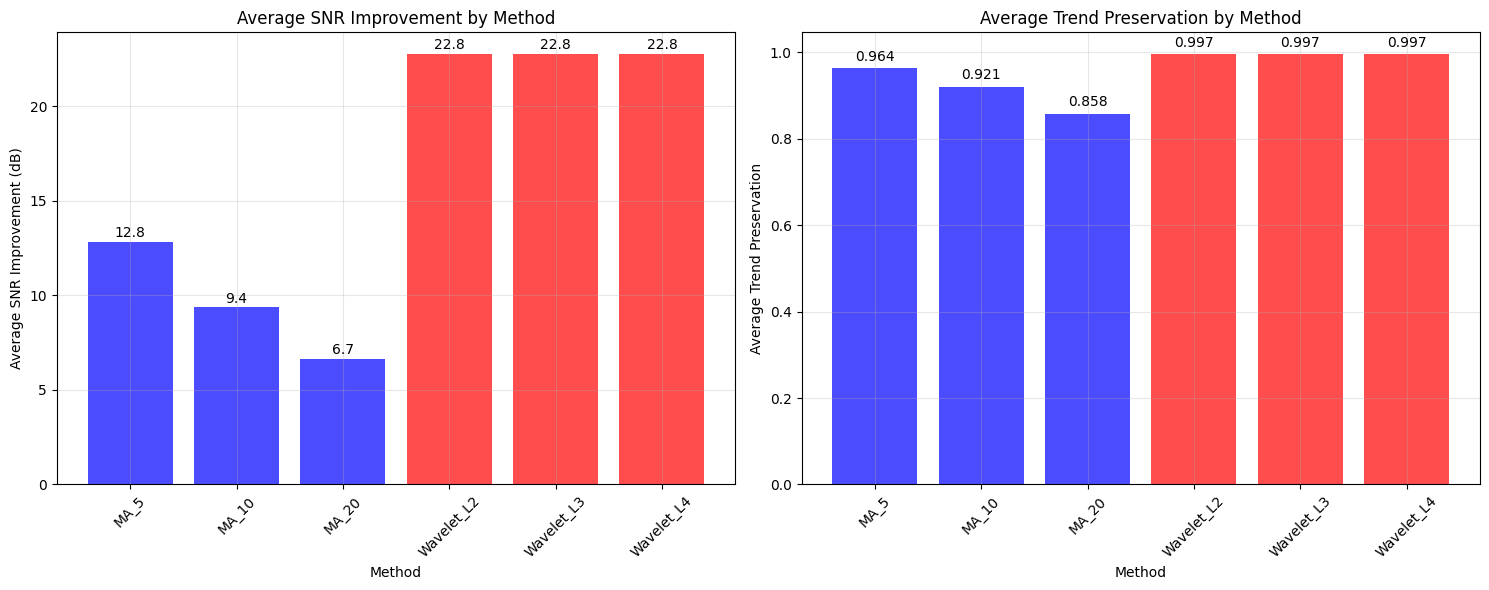


Comprehensive Method Evaluation Summary:
Method          Avg SNR (dB)    Avg Trend Pres. Datasets  
----------------------------------------------------------------------
MA_5            12.81           0.964           9         
MA_10           9.36            0.921           9         
MA_20           6.65            0.858           9         
Wavelet_L2      22.77           0.997           9         
Wavelet_L3      22.77           0.997           9         
Wavelet_L4      22.77           0.997           9         


In [ ]:
def comprehensive_method_evaluation(stock_data, environmental_data):
    """Comprehensive evaluation across multiple datasets."""
    evaluation_results = {}
    
    # Test on stock data
    for symbol, prices in stock_data.items():
        if len(prices) < 100:  # Skip if insufficient data
            continue
        
        dates = pd.date_range(start='2023-01-01', periods=len(prices), freq='B')
        comparison = compare_methods(prices, dates)
        denoised_methods = {k: v for k, v in comparison.items() 
                           if k not in ['original', 'dates']}
        metrics = calculate_performance_metrics(prices, denoised_methods)
        evaluation_results[f'Stock_{symbol}'] = metrics
    
    # Test on environmental data
    for city, data in environmental_data.items():
        values = data['values']
        if len(values) < 100:
            continue
        
        dates = pd.to_datetime(data['dates'])
        comparison = compare_methods(values, dates)
        denoised_methods = {k: v for k, v in comparison.items() 
                           if k not in ['original', 'dates']}
        metrics = calculate_performance_metrics(values, denoised_methods)
        evaluation_results[f'Environment_{city}'] = metrics
    
    return evaluation_results

# Perform comprehensive evaluation
comprehensive_results = comprehensive_method_evaluation(stock_data, environmental_data)

# Aggregate results by method
method_performance = {}
for dataset, methods in comprehensive_results.items():
    for method_name, metrics in methods.items():
        if method_name not in method_performance:
            method_performance[method_name] = {'SNR_improvement': [], 'Trend_preservation': []}
        
        method_performance[method_name]['SNR_improvement'].append(metrics['SNR_improvement'])
        method_performance[method_name]['Trend_preservation'].append(metrics['Trend_preservation'])

# Calculate average performance
average_performance = {}
for method, performance in method_performance.items():
    average_performance[method] = {
        'Avg_SNR': np.mean([x for x in performance['SNR_improvement'] if not np.isinf(x)]),
        'Avg_Trend_Preservation': np.mean(performance['Trend_preservation']),
        'Datasets_Tested': len(performance['SNR_improvement'])
    }

# Visualize average performance
methods = list(average_performance.keys())
snr_values = [average_performance[m]['Avg_SNR'] for m in methods]
trend_values = [average_performance[m]['Avg_Trend_Preservation'] for m in methods]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# SNR Improvement
colors = ['blue' if 'MA_' in m else 'red' for m in methods]
bars1 = ax1.bar(range(len(methods)), snr_values, color=colors, alpha=0.7)
ax1.set_xlabel('Method')
ax1.set_ylabel('Average SNR Improvement (dB)')
ax1.set_title('Average SNR Improvement by Method')
ax1.set_xticks(range(len(methods)))
ax1.set_xticklabels(methods, rotation=45)
ax1.grid(True, alpha=0.3)

# Add value labels on bars
for i, (bar, value) in enumerate(zip(bars1, snr_values)):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1, 
             f'{value:.1f}', ha='center', va='bottom')

# Trend Preservation
bars2 = ax2.bar(range(len(methods)), trend_values, color=colors, alpha=0.7)
ax2.set_xlabel('Method')
ax2.set_ylabel('Average Trend Preservation')
ax2.set_title('Average Trend Preservation by Method')
ax2.set_xticks(range(len(methods)))
ax2.set_xticklabels(methods, rotation=45)
ax2.grid(True, alpha=0.3)

# Add value labels on bars
for i, (bar, value) in enumerate(zip(bars2, trend_values)):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{value:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.savefig('./output/comprehensive_method_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nComprehensive Method Evaluation Summary:")
print("="*70)
print(f"{'Method':<15} {'Avg SNR (dB)':<15} {'Avg Trend Pres.':<15} {'Datasets':<10}")
print("-"*70)
for method, results in average_performance.items():
    print(f"{method:<15} {results['Avg_SNR']:<15.2f} {results['Avg_Trend_Preservation']:<15.3f} {results['Datasets_Tested']:<10}")

## 3.8 Advanced Applications

### 3.8.1 Real-time Anomaly Detection System

Real-time Anomaly Detection Simulation
ANOMALY DETECTED at step 94: Value=55.07, Score=1.04, Baseline Dev=-0.66
ANOMALY DETECTED at step 134: Value=43.17, Score=1.10, Baseline Dev=-1.76


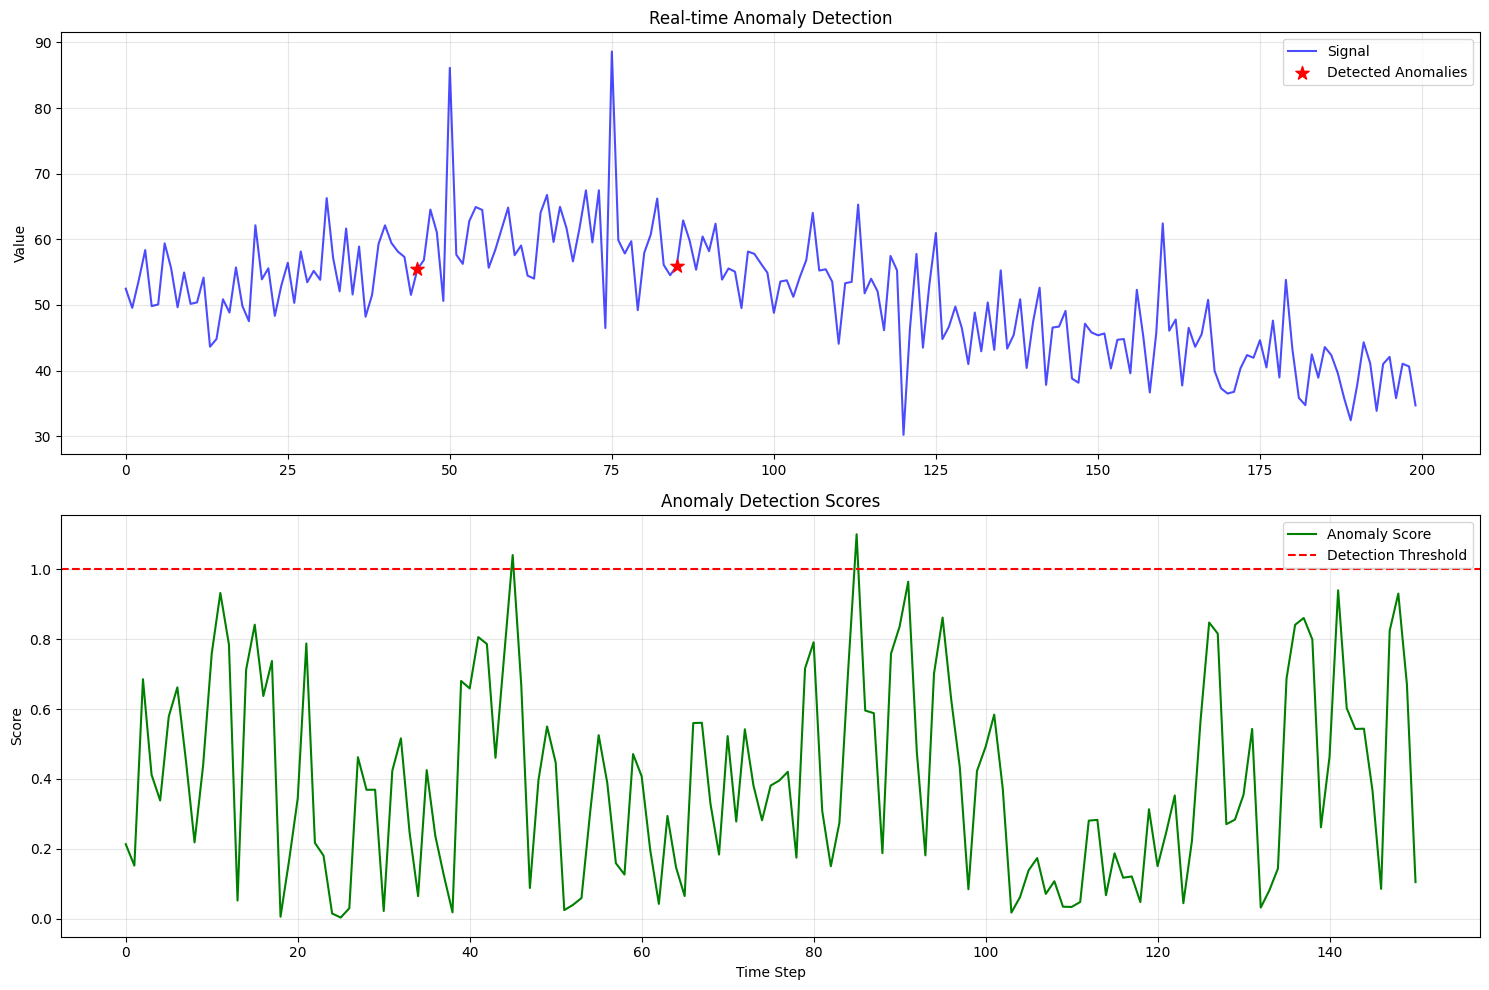


Total anomalies detected: 2


In [ ]:
import numpy as np
import pywt
from datetime import datetime, timedelta
import matplotlib.pyplot as plt


class RealTimeWaveletAnalyzer:
    """Real-time wavelet-based anomaly detection system."""
    
    def __init__(self, window_size=100, wavelet='db4', levels=3, threshold_factor=2.5):
        self.window_size = window_size
        self.wavelet = wavelet
        self.levels = levels
        self.threshold_factor = threshold_factor
        self.buffer = []
        self.anomaly_history = []
        self.baseline_stats = None
        
    def add_data_point(self, value, timestamp=None):
        """Add a new data point and check for anomalies."""
        if timestamp is None:
            timestamp = datetime.now()
        
        self.buffer.append({'value': value, 'timestamp': timestamp})
        
        # Maintain buffer size
        if len(self.buffer) > self.window_size:
            self.buffer.pop(0)
        
        # Perform analysis if buffer is full
        if len(self.buffer) == self.window_size:
            return self._analyze_current_window()
        
        return None
    
    def _analyze_current_window(self):
        """Analyze current window for anomalies."""
        values = np.array([point['value'] for point in self.buffer])
        
        # Update baseline statistics
        if self.baseline_stats is None:
            self.baseline_stats = {
                'mean': np.mean(values),
                'std': np.std(values),
                'median': np.median(values)
            }
        else:
            # Exponential moving average for baseline update
            alpha = 0.1
            self.baseline_stats['mean'] = alpha * np.mean(values) + (1 - alpha) * self.baseline_stats['mean']
            self.baseline_stats['std'] = alpha * np.std(values) + (1 - alpha) * self.baseline_stats['std']
            self.baseline_stats['median'] = alpha * np.median(values) + (1 - alpha) * self.baseline_stats['median']
        
        # Wavelet analysis
        try:
            coeffs = pywt.wavedec(values, self.wavelet, level=self.levels)
            detail_coeffs = coeffs[1] if len(coeffs) > 1 else coeffs[0]
            
            # Adaptive threshold
            threshold = self.threshold_factor * np.std(detail_coeffs)
            
            # Check for anomaly in the most recent point
            recent_coeff_idx = -1  # Most recent coefficient
            is_anomaly = np.abs(detail_coeffs[recent_coeff_idx]) > threshold
            
            current_point = self.buffer[-1]
            anomaly_info = {
                'timestamp': current_point['timestamp'],
                'value': current_point['value'],
                'is_anomaly': is_anomaly,
                'anomaly_score': np.abs(detail_coeffs[recent_coeff_idx]) / threshold if threshold > 0 else 0,
                'baseline_deviation': (current_point['value'] - self.baseline_stats['mean']) / self.baseline_stats['std']
            }
            
            if is_anomaly:
                self.anomaly_history.append(anomaly_info)
            
            return anomaly_info
            
        except Exception as e:
            print(f"Error in wavelet analysis: {e}")
            return None
    
    def get_recent_anomalies(self, hours=24):
        """Get anomalies from the last N hours."""
        cutoff_time = datetime.now() - timedelta(hours=hours)
        return [anomaly for anomaly in self.anomaly_history 
                if anomaly['timestamp'] > cutoff_time]

# Demonstrate real-time system with simulated data
def simulate_real_time_data():
    """Simulate real-time data with embedded anomalies."""
    np.random.seed(42)
    
    # Create base signal with trend and noise
    t = np.linspace(0, 10, 200)
    base_signal = 50 + 10 * np.sin(0.5 * t) + 5 * np.random.randn(len(t))
    
    # Add some anomalies
    anomaly_indices = [50, 75, 120, 160]
    for idx in anomaly_indices:
        if idx < len(base_signal):
            base_signal[idx] += np.random.choice([-1, 1]) * 25  # Large spike/drop
    
    return base_signal

# Run real-time simulation
print("Real-time Anomaly Detection Simulation")
print("="*50)

analyzer = RealTimeWaveletAnalyzer(window_size=50, threshold_factor=2.0)
simulated_data = simulate_real_time_data()

results = []
for i, value in enumerate(simulated_data):
    result = analyzer.add_data_point(value, datetime.now() + timedelta(seconds=i))
    if result:
        results.append(result)
        if result['is_anomaly']:
            print(f"ANOMALY DETECTED at step {i}: "
                  f"Value={value:.2f}, Score={result['anomaly_score']:.2f}, "
                  f"Baseline Dev={result['baseline_deviation']:.2f}")

# Visualize real-time results
if results:
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10))
    
    # Plot signal with detected anomalies
    steps = range(len(simulated_data))
    ax1.plot(steps, simulated_data, 'b-', alpha=0.7, label='Signal')
    
    anomaly_steps = [i for i, result in enumerate(results) if result['is_anomaly']]
    if anomaly_steps:
        ax1.scatter([steps[i] for i in anomaly_steps], 
                   [simulated_data[i] for i in anomaly_steps],
                   color='red', s=100, marker='*', label='Detected Anomalies', zorder=5)
    
    ax1.set_title('Real-time Anomaly Detection')
    ax1.set_ylabel('Value')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Plot anomaly scores
    anomaly_scores = [r['anomaly_score'] for r in results]
    baseline_devs = [r['baseline_deviation'] for r in results]
    
    ax2.plot(range(len(anomaly_scores)), anomaly_scores, 'g-', label='Anomaly Score')
    ax2.axhline(y=1.0, color='r', linestyle='--', label='Detection Threshold')
    ax2.set_title('Anomaly Detection Scores')
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('Score')
    ax2.legend()
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('./output/real_time_anomaly_detection.png', dpi=300, bbox_inches='tight')
    plt.show()

print(f"\nTotal anomalies detected: {len(analyzer.anomaly_history)}")

## 3.9 Practical Considerations


Benchmarking signal length: 100
  db4: 0.39 ms
  db8: 0.29 ms
  haar: 0.18 ms
  sym5: 0.19 ms

Benchmarking signal length: 500
  db4: 0.18 ms
  db8: 0.11 ms
  haar: 0.10 ms
  sym5: 0.09 ms

Benchmarking signal length: 1000
  db4: 0.11 ms
  db8: 0.11 ms
  haar: 0.10 ms
  sym5: 0.10 ms

Benchmarking signal length: 5000
  db4: 0.16 ms
  db8: 0.19 ms
  haar: 0.14 ms
  sym5: 0.17 ms

Benchmarking signal length: 10000
  db4: 0.22 ms
  db8: 0.30 ms
  haar: 0.18 ms
  sym5: 0.24 ms


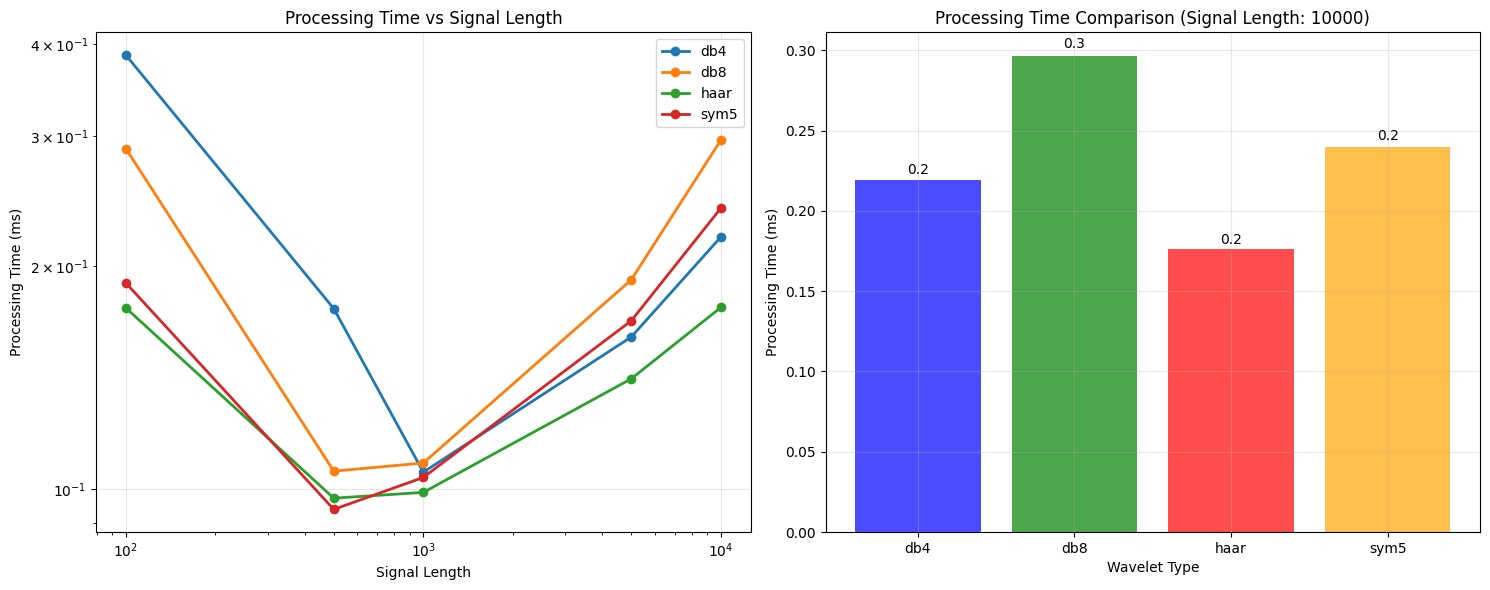

In [ ]:
import numpy as np
import pywt
import time
import matplotlib.pyplot

def benchmark_wavelet_methods():
    """Benchmark different wavelet methods for performance."""
    signal_lengths = [100, 500, 1000, 5000, 10000]
    wavelets = ['db4', 'db8', 'haar', 'sym5']
    
    results = {}
    
    for length in signal_lengths:
        print(f"\nBenchmarking signal length: {length}")
        # Generate test signal
        np.random.seed(42)
        test_signal = np.random.randn(length)
        
        results[length] = {}
        
        for wavelet in wavelets:
            times = []
            for _ in range(5):  # Average over 5 runs
                start_time = time.time()
                
                try:
                    # Forward transform
                    coeffs = pywt.wavedec(test_signal, wavelet, level=4)
                    
                    # Thresholding
                    threshold = 0.1 * np.max([np.max(np.abs(c)) for c in coeffs])
                    denoised_coeffs = [pywt.threshold(c, threshold, mode='soft') for c in coeffs]
                    
                    # Inverse transform
                    reconstructed = pywt.waverec(denoised_coeffs, wavelet)
                    
                    end_time = time.time()
                    times.append(end_time - start_time)
                    
                except Exception as e:
                    print(f"Error with {wavelet} at length {length}: {e}")
                    times.append(np.nan)
            
            avg_time = np.nanmean(times) * 1000  # Convert to milliseconds
            results[length][wavelet] = avg_time
            print(f"  {wavelet}: {avg_time:.2f} ms")
    
    return results

def plot_performance_benchmark(results):
    """Plot performance benchmark results."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
    
    lengths = list(results.keys())
    wavelets = list(results[lengths[0]].keys())
    
    # Performance vs signal length
    for wavelet in wavelets:
        times = [results[length][wavelet] for length in lengths]
        ax1.plot(lengths, times, marker='o', label=wavelet, linewidth=2)
    
    ax1.set_xlabel('Signal Length')
    ax1.set_ylabel('Processing Time (ms)')
    ax1.set_title('Processing Time vs Signal Length')
    ax1.set_xscale('log')
    ax1.set_yscale('log')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    
    # Relative performance for largest signal
    largest_signal = max(lengths)
    times_large = [results[largest_signal][wavelet] for wavelet in wavelets]
    bars = ax2.bar(wavelets, times_large, alpha=0.7, 
                   color=['blue', 'green', 'red', 'orange'])
    ax2.set_xlabel('Wavelet Type')
    ax2.set_ylabel('Processing Time (ms)')
    ax2.set_title(f'Processing Time Comparison (Signal Length: {largest_signal})')
    ax2.grid(True, alpha=0.3)
    
    # Add value labels
    for bar, time_val in zip(bars, times_large):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + bar.get_height()*0.01,
                f'{time_val:.1f}', ha='center', va='bottom')
    
    plt.tight_layout()
    return fig

# Run benchmark
benchmark_results = benchmark_wavelet_methods()
fig = plot_performance_benchmark(benchmark_results)
plt.savefig('./output/wavelet_performance_benchmark.png', dpi=300, bbox_inches='tight')
plt.show()

### 3.9.2 Parameter Selection Guidelines

In [ ]:
# Libraries needed for code in section 12.9.2 Parameter Selection Guidelines
import numpy as np
import pywt

def wavelet_parameter_guide():
    """Provide guidance for parameter selection."""
    
    guidelines = {
        "Wavelet Selection": {
            "Daubechies (db4, db8)": "General purpose, good for most financial and environmental data",
            "Haar": "Simple, fast computation, good for sharp discontinuities",
            "Symlets (sym4, sym8)": "Nearly symmetric, good for analysis applications",
            "Biorthogonal (bior2.2)": "Symmetric, good reconstruction properties"
        },
        
        "Decomposition Levels": {
            "Level 2-3": "Short-term patterns, daily variations, high-frequency noise",
            "Level 4-5": "Medium-term trends, weekly/monthly patterns",
            "Level 6+": "Long-term trends, seasonal patterns (requires long signals)"
        },
        
        "Thresholding": {
            "Soft thresholding": "Smooth denoising, preserves signal continuity",
            "Hard thresholding": "Sharp noise removal, may introduce artifacts",
            "Universal threshold": "σ√(2ln(N)) - good general purpose threshold",
            "Adaptive threshold": "Based on coefficient statistics - more robust"
        },
        
        "Data Requirements": {
            "Minimum length": "64-100 points for meaningful decomposition",
            "Recommended length": "256+ points for stable results",
            "Sampling rate": "Should be appropriate for phenomena of interest",
            "Data quality": "Handle missing values and outliers before analysis"
        }
    }
    
    print("Wavelet Parameter Selection Guide")
    print("=" * 60)
    
    for category, items in guidelines.items():
        print(f"\n{category}:")
        print("-" * len(category))
        for param, description in items.items():
            print(f"  {param:<20}: {description}")
    
    return guidelines

# Display parameter guide
parameter_guide = wavelet_parameter_guide()


Wavelet Parameter Selection Guide

Wavelet Selection:
-----------------
  Daubechies (db4, db8): General purpose, good for most financial and environmental data
  Haar                : Simple, fast computation, good for sharp discontinuities
  Symlets (sym4, sym8): Nearly symmetric, good for analysis applications
  Biorthogonal (bior2.2): Symmetric, good reconstruction properties

Decomposition Levels:
--------------------
  Level 2-3           : Short-term patterns, daily variations, high-frequency noise
  Level 4-5           : Medium-term trends, weekly/monthly patterns
  Level 6+            : Long-term trends, seasonal patterns (requires long signals)

Thresholding:
------------
  Soft thresholding   : Smooth denoising, preserves signal continuity
  Hard thresholding   : Sharp noise removal, may introduce artifacts
  Universal threshold : σ√(2ln(N)) - good general purpose threshold
  Adaptive threshold  : Based on coefficient statistics - more robust

Data Requirements:
------------


### 3.9.3 Error Handling and Robustness


In [ ]:
import numpy as np
import pywt

def robust_wavelet_analysis(signal, fallback_params=None):
    """Robust wavelet analysis with comprehensive error handling."""
    
    if fallback_params is None:
        fallback_params = {
            'wavelets': ['db4', 'db2', 'haar'],
            'levels': [4, 3, 2],
            'threshold_modes': ['soft', 'hard']
        }
    
    # Input validation
    if not isinstance(signal, np.ndarray):
        signal = np.array(signal)
    
    if len(signal) < 8:
        raise ValueError(f"Signal too short: {len(signal)} points. Minimum: 8 points")
    
    # Handle missing values
    if np.any(np.isnan(signal)):
        print("Warning: NaN values detected. Interpolating...")
        valid_indices = ~np.isnan(signal)
        if np.sum(valid_indices) < len(signal) // 2:
            raise ValueError("Too many missing values (>50%)")
        
        # Linear interpolation
        signal = np.interp(np.arange(len(signal)), 
                          np.arange(len(signal))[valid_indices], 
                          signal[valid_indices])
    
    # Try different parameter combinations
    for wavelet in fallback_params['wavelets']:
        for level in fallback_params['levels']:
            for threshold_mode in fallback_params['threshold_modes']:
                try:
                    # Adjust level based on signal length
                    max_level = pywt.dwt_max_level(len(signal), wavelet)
                    actual_level = min(level, max_level)
                    
                    if actual_level < 1:
                        continue
                    
                    # Decompose
                    coeffs = pywt.wavedec(signal, wavelet, level=actual_level)
                    
                    # Calculate robust threshold
                    detail_coeffs = np.concatenate([c for c in coeffs[1:]])
                    if len(detail_coeffs) == 0:
                        continue
                    
                    # Use median absolute deviation for robustness
                    mad = np.median(np.abs(detail_coeffs - np.median(detail_coeffs)))
                    threshold = 3 * mad / 0.6745
                    
                    if threshold == 0:
                        threshold = np.std(detail_coeffs) * np.sqrt(2 * np.log(len(signal)))
                    
                    # Apply thresholding
                    denoised_coeffs = [coeffs[0]]  # Keep approximation
                    for c in coeffs[1:]:
                        denoised_coeffs.append(pywt.threshold(c, threshold, mode=threshold_mode))
                    
                    # Reconstruct
                    reconstructed = pywt.waverec(denoised_coeffs, wavelet)
                    
                    # Ensure proper length
                    if len(reconstructed) > len(signal):
                        reconstructed = reconstructed[:len(signal)]
                    elif len(reconstructed) < len(signal):
                        # Pad with last value
                        pad_length = len(signal) - len(reconstructed)
                        reconstructed = np.concatenate([reconstructed, 
                                                      np.full(pad_length, reconstructed[-1])])
                    
                    # Validate result
                    if np.any(np.isnan(reconstructed)) or np.any(np.isinf(reconstructed)):
                        continue
                    
                    # Success - return results
                    return {
                        'denoised': reconstructed,
                        'coeffs': coeffs,
                        'wavelet': wavelet,
                        'level': actual_level,
                        'threshold': threshold,
                        'threshold_mode': threshold_mode,
                        'success': True,
                        'message': f'Successfully processed with {wavelet}, level {actual_level}'
                    }
                    
                except Exception as e:
                    print(f"Failed with {wavelet}, level {level}, mode {threshold_mode}: {e}")
                    continue
    
    # If all methods failed
    return {
        'denoised': signal,  # Return original signal
        'coeffs': None,
        'wavelet': None,
        'level': None,
        'threshold': None,
        'threshold_mode': None,
        'success': False,
        'message': 'All wavelet methods failed. Returning original signal.'
    }

# Test robust analysis with problematic data
def test_robustness():
    """Test robustness with various problematic signals."""
    test_cases = {
        'Normal signal': np.random.randn(200),
        'Signal with NaN': np.concatenate([np.random.randn(100), [np.nan] * 10, np.random.randn(90)]),
        'Very short signal': np.random.randn(10),
        'Constant signal': np.ones(100),
        'Signal with outliers': np.concatenate([np.random.randn(180), [100, -100] * 10])
    }
    
    print("Robustness Testing Results:")
    print("=" * 50)
    
    for name, signal in test_cases.items():
        try:
            result = robust_wavelet_analysis(signal)
            status = "✓ SUCCESS" if result['success'] else "✗ FAILED"
            print(f"{name:<20}: {status}")
            print(f"                    {result['message']}")
        except Exception as e:
            print(f"{name:<20}: ✗ ERROR - {e}")
        print()

# Run robustness tests
test_robustness()

Robustness Testing Results:
Normal signal       : ✓ SUCCESS
                    Successfully processed with db4, level 4

Signal with NaN     : ✓ SUCCESS
                    Successfully processed with db4, level 4

Very short signal   : ✓ SUCCESS
                    Successfully processed with db2, level 1

Constant signal     : ✓ SUCCESS
                    Successfully processed with db4, level 3

Signal with outliers: ✓ SUCCESS
                    Successfully processed with db4, level 4



## 3.10 Advanced Wavelet Applications

### 3.10.1 Multi-asset Portfolio Analysis

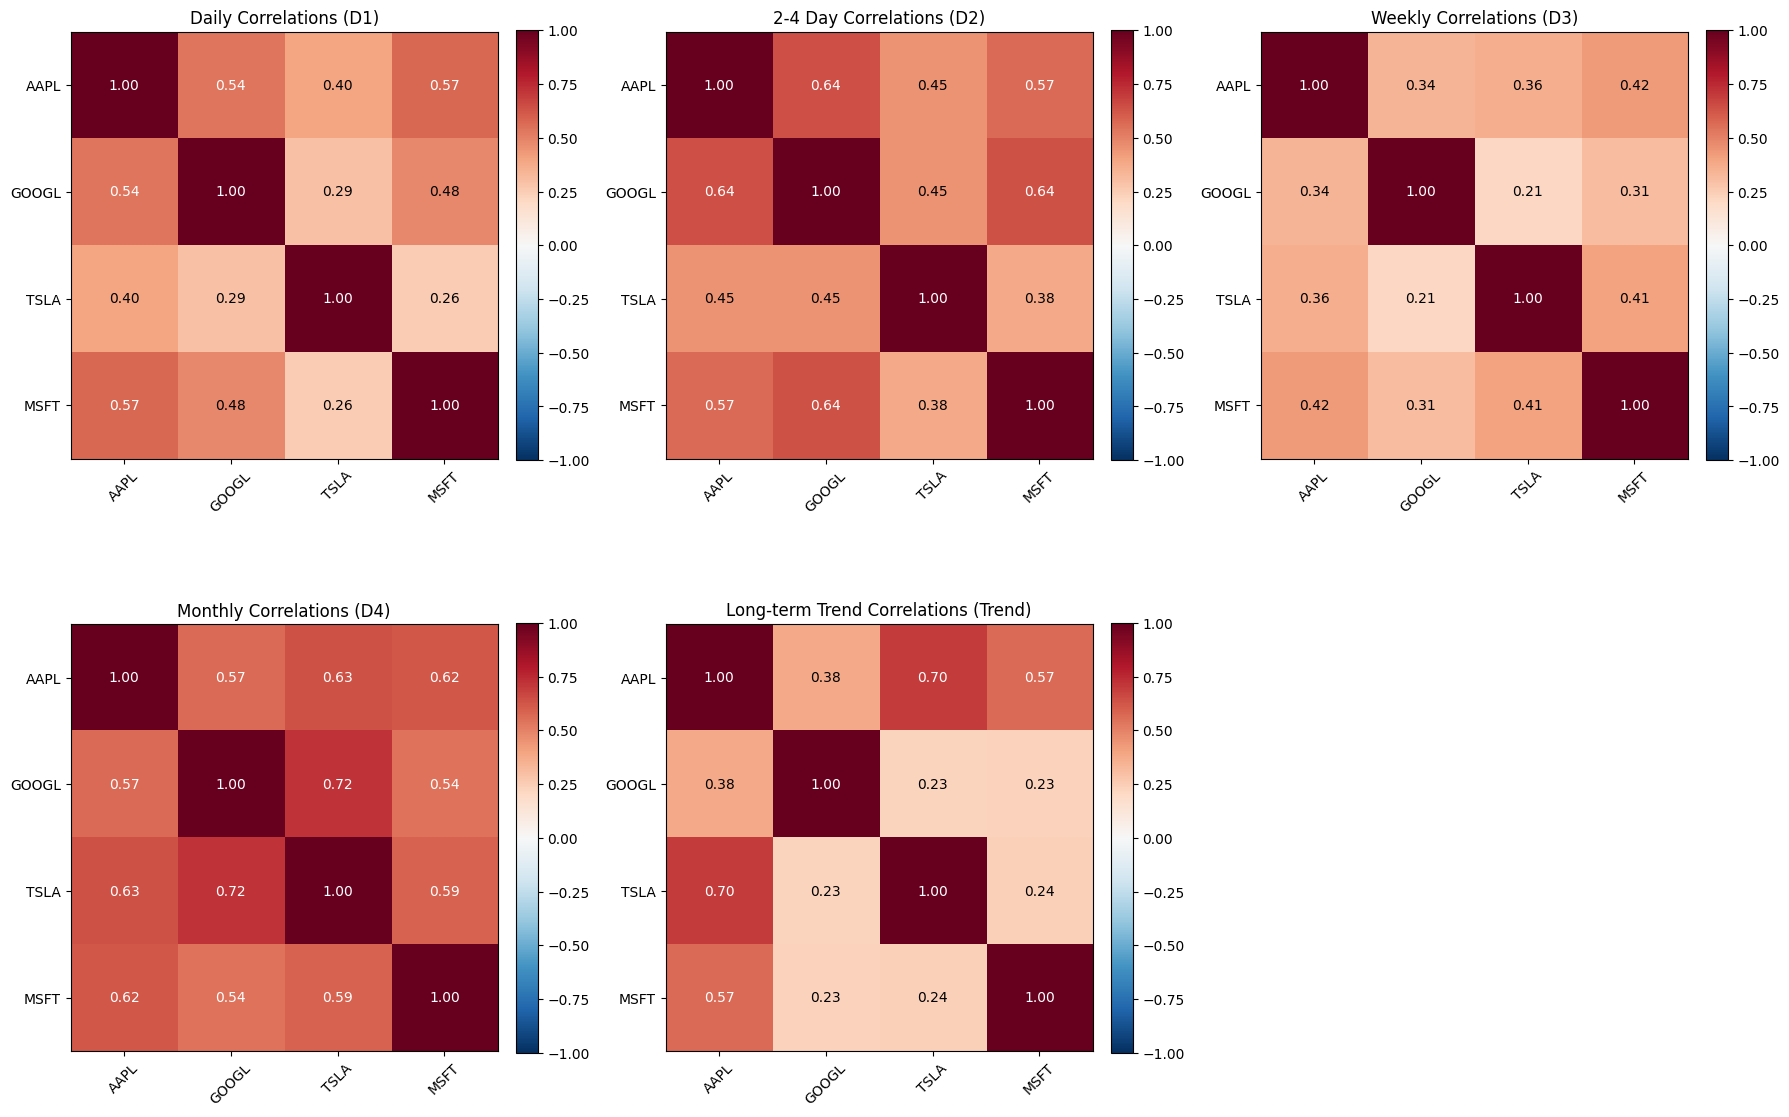

Portfolio Scale-wise Correlation Analysis:
D1        : Average correlation = 0.422
D2        : Average correlation = 0.521
D3        : Average correlation = 0.342
D4        : Average correlation = 0.612
Trend     : Average correlation = 0.389


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

def portfolio_wavelet_analysis(stock_data, wavelet='db4', max_level=4):
    """Robust portfolio analysis using wavelet decomposition and scale-wise correlations."""
    
    if len(stock_data) < 2:
        print("Need at least 2 assets for portfolio analysis")
        return None
    
    # Align all assets to same length
    min_length = min(len(prices) for prices in stock_data.values())
    if min_length < 2:
        print("Not enough data points for wavelet analysis")
        return None
    
    aligned_data = {sym: np.array(prices[:min_length]) for sym, prices in stock_data.items()}
    
    # Compute log returns and filter valid assets
    returns_data = {}
    for sym, prices in aligned_data.items():
        returns = np.diff(np.log(prices))
        returns = returns[~np.isnan(returns)]  # Remove NaNs
        if len(returns) < 2:
            print(f"Skipping {sym}: insufficient return data")
            continue
        returns_data[sym] = returns
    
    if len(returns_data) < 2:
        print("Not enough valid assets for correlation analysis")
        return None
    
    # Wavelet decomposition
    wavelet_components = {}
    for sym, returns in returns_data.items():
        level = min(max_level, pywt.dwt_max_level(len(returns), wavelet))
        if level < 1:
            print(f"Skipping {sym}: decomposition level too small")
            continue
        coeffs = pywt.wavedec(returns, wavelet, level=level)
        
        components = {}
        # Detail coefficients
        for i in range(1, len(coeffs)):
            temp = [np.zeros_like(c) for c in coeffs]
            temp[i] = coeffs[i]
            comp = pywt.waverec(temp, wavelet)
            comp = comp[:len(returns)]
            components[f'D{len(coeffs)-i}'] = comp
        # Approximation (trend)
        temp = [coeffs[0]] + [np.zeros_like(c) for c in coeffs[1:]]
        trend = pywt.waverec(temp, wavelet)
        trend = trend[:len(returns)]
        components['Trend'] = trend
        
        wavelet_components[sym] = components
    
    symbols = list(wavelet_components.keys())
    
    # Scale-wise correlation
    scale_correlations = {}
    scales = [f'D{i}' for i in range(1, max_level+1)] + ['Trend']
    
    for scale in scales:
        corr_matrix = np.zeros((len(symbols), len(symbols)))
        for i, sym1 in enumerate(symbols):
            for j, sym2 in enumerate(symbols):
                comp1 = wavelet_components[sym1].get(scale)
                comp2 = wavelet_components[sym2].get(scale)
                if comp1 is not None and comp2 is not None:
                    min_len = min(len(comp1), len(comp2))
                    corr = np.corrcoef(comp1[:min_len], comp2[:min_len])[0, 1]
                    corr_matrix[i, j] = corr if not np.isnan(corr) else 0
        scale_correlations[scale] = corr_matrix
    
    return {
        'symbols': symbols,
        'wavelet_components': wavelet_components,
        'scale_correlations': scale_correlations,
        'returns_data': returns_data
    }


def plot_scale_correlations(portfolio_analysis):
    """Plot correlation matrices at different scales."""
    if portfolio_analysis is None:
        return
    
    symbols = portfolio_analysis['symbols']
    scale_correlations = portfolio_analysis['scale_correlations']
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()
    
    scales = ['D1', 'D2', 'D3', 'D4', 'Trend']
    scale_labels = ['Daily', '2-4 Day', 'Weekly', 'Monthly', 'Long-term Trend']
    
    for i, (scale, label) in enumerate(zip(scales, scale_labels)):
        if scale in scale_correlations:
            corr_matrix = scale_correlations[scale]
            im = axes[i].imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1)
            axes[i].set_title(f'{label} Correlations ({scale})')
            
            for row in range(len(symbols)):
                for col in range(len(symbols)):
                    axes[i].text(col, row, f'{corr_matrix[row, col]:.2f}',
                                 ha="center", va="center",
                                 color="black" if abs(corr_matrix[row, col]) < 0.5 else "white")
            
            axes[i].set_xticks(range(len(symbols)))
            axes[i].set_yticks(range(len(symbols)))
            axes[i].set_xticklabels(symbols, rotation=45)
            axes[i].set_yticklabels(symbols)
            plt.colorbar(im, ax=axes[i], fraction=0.046, pad=0.04)
    
    if len(scales) < len(axes):
        axes[-1].set_visible(False)
    
    plt.tight_layout()
    plt.savefig('./output/portfolio_scale_correlations.png', dpi=300, bbox_inches='tight')
    plt.show()

# Perform portfolio analysis if we have stock data
if len(stock_data) >= 2:
    portfolio_results = portfolio_wavelet_analysis(stock_data)
    if portfolio_results:
        plot_scale_correlations(portfolio_results)
        
        print("Portfolio Scale-wise Correlation Analysis:")
        print("=" * 50)
        for scale, matrix in portfolio_results['scale_correlations'].items():
            avg_correlation = np.mean(matrix[np.triu_indices_from(matrix, k=1)])
            print(f"{scale:<10}: Average correlation = {avg_correlation:.3f}")


### 3.10.2 Environmental Monitoring Network Analysis

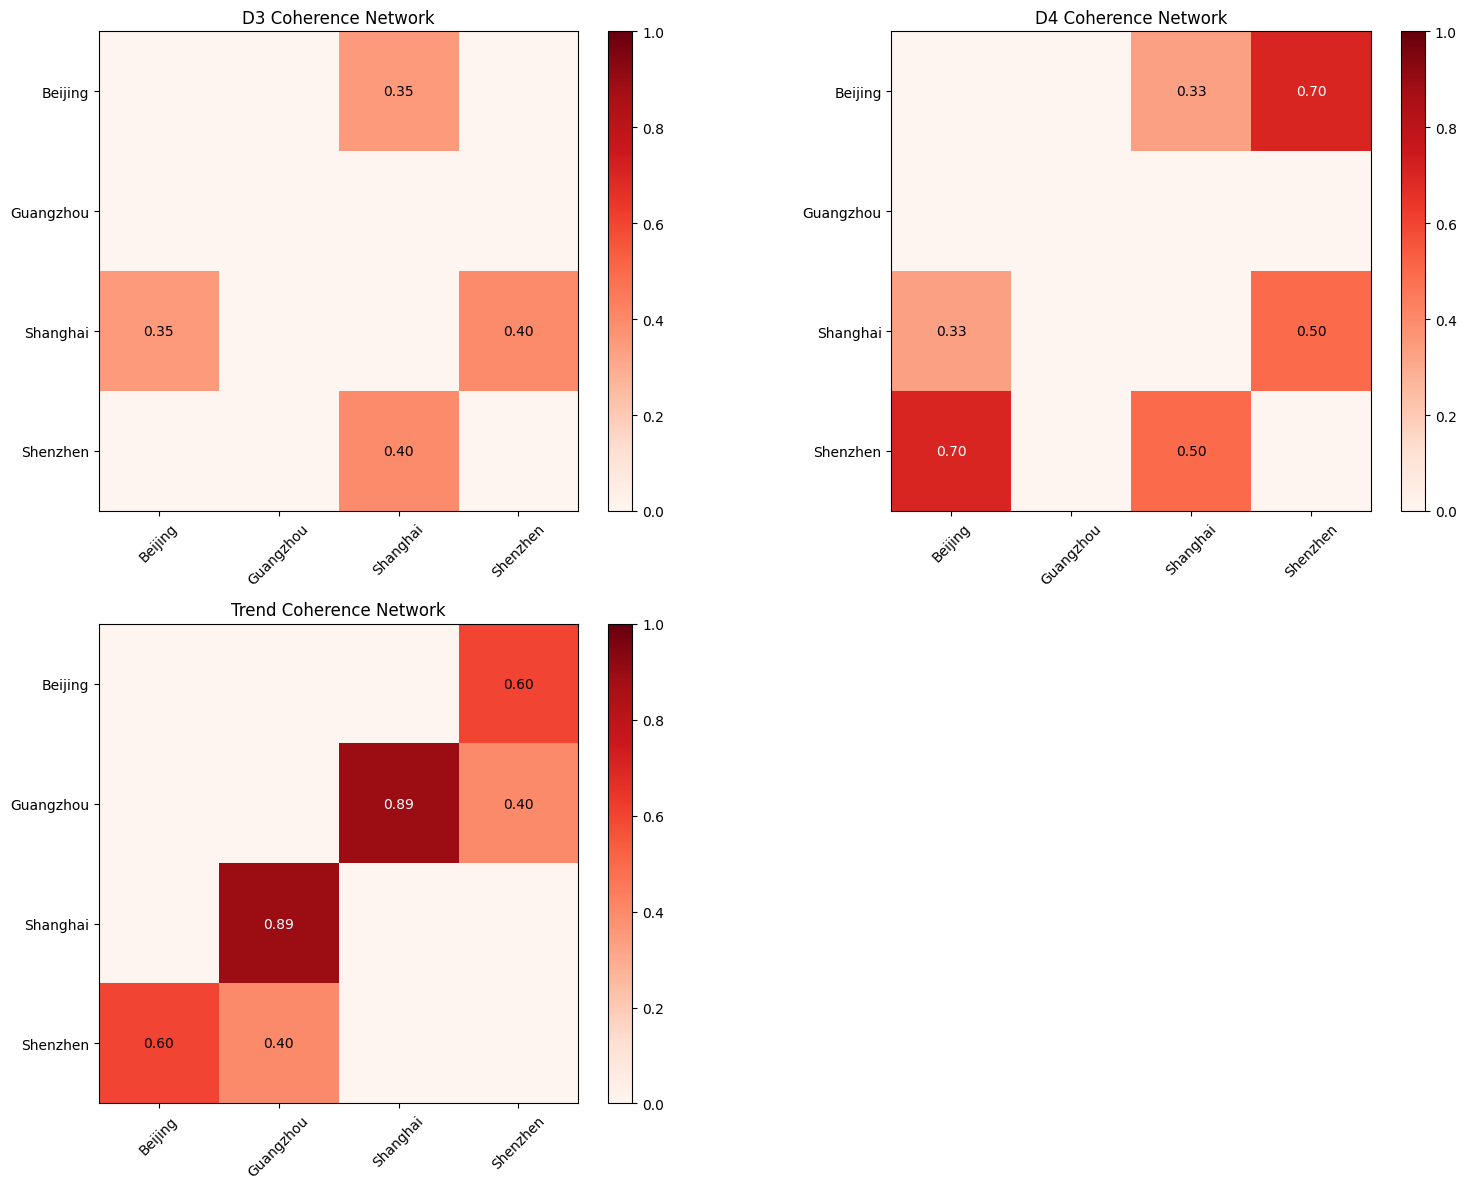


Environmental Network Analysis Summary:
D3:
  Active connections: 2
  Average coherence: 0.373
  Maximum coherence: 0.396
D4:
  Active connections: 3
  Average coherence: 0.511
  Maximum coherence: 0.702
Trend:
  Active connections: 3
  Average coherence: 0.631
  Maximum coherence: 0.891


In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

def environmental_network_analysis(environmental_data, wavelet='db4', min_length=50):
    """Analyze environmental monitoring network using wavelet coherence."""
    
    cities = list(environmental_data.keys())
    if len(cities) < 2:
        print("Need at least 2 cities for network analysis")
        return None

    # Align data lengths and fill missing values
    aligned_data = {}
    max_len = max(len(data['values']) for data in environmental_data.values())
    for city, data in environmental_data.items():
        series = np.array(data['values'], dtype=float)
        # Fill missing values
        for i in range(len(series)):
            if np.isnan(series[i]):
                series[i] = series[i-1] if i > 0 else 0
        # Pad to max length
        if len(series) < max_len:
            series = np.pad(series, (0, max_len - len(series)), 'edge')
        aligned_data[city] = series

    # Compute wavelet coherence for city pairs
    coherence_results = {}
    for i, city1 in enumerate(cities):
        for j, city2 in enumerate(cities[i+1:], i+1):
            signal1 = aligned_data[city1]
            signal2 = aligned_data[city2]

            if len(signal1) < min_length or len(signal2) < min_length:
                continue

            # Determine safe decomposition level based on shortest signal
            max_level = min(4, pywt.dwt_max_level(len(signal1), wavelet),
                                 pywt.dwt_max_level(len(signal2), wavelet))
            if max_level < 1:
                continue

            coeffs1 = pywt.wavedec(signal1, wavelet, level=max_level)
            coeffs2 = pywt.wavedec(signal2, wavelet, level=max_level)

            scale_coherence = {}
            for level in range(1, len(coeffs1)):
                detail1 = coeffs1[level]
                detail2 = coeffs2[level]
                min_len_level = min(len(detail1), len(detail2))
                if min_len_level > 10:
                    corr = np.abs(np.corrcoef(detail1[:min_len_level],
                                              detail2[:min_len_level])[0,1])
                    scale_coherence[f'D{len(coeffs1)-level}'] = corr if not np.isnan(corr) else 0

            # Approximation / trend
            trend1 = pywt.waverec([coeffs1[0]] + [np.zeros_like(c) for c in coeffs1[1:]], wavelet)
            trend2 = pywt.waverec([coeffs2[0]] + [np.zeros_like(c) for c in coeffs2[1:]], wavelet)
            min_len_trend = min(len(trend1), len(trend2))
            scale_coherence['Trend'] = np.abs(np.corrcoef(trend1[:min_len_trend],
                                                          trend2[:min_len_trend])[0,1])

            coherence_results[(city1, city2)] = scale_coherence

    if not coherence_results:
        print("No valid city pairs for coherence analysis")
        return None

    return coherence_results

def plot_environmental_network(coherence_results, threshold=0.5):
    """Plot environmental monitoring network based on wavelet coherence."""
    
    if not coherence_results:
        print("No coherence results to plot")
        return

    cities = set()
    for city_pair in coherence_results.keys():
        cities.update(city_pair)
    cities = sorted(list(cities))
    n_cities = len(cities)

    # Collect scales present in any pair
    all_scales = set()
    for scales in coherence_results.values():
        all_scales.update(scales.keys())
    all_scales = sorted(all_scales, key=lambda x: (x[0], int(x[1:]) if x[0]=='D' else 0))
    
    # Only keep scales that have at least one non-zero coherence above threshold
    valid_scales = []
    for scale in all_scales:
        has_connection = any(coherences.get(scale,0) > threshold for coherences in coherence_results.values())
        if has_connection:
            valid_scales.append(scale)
    
    n_valid = len(valid_scales)
    if n_valid == 0:
        print("No valid scales with active connections above threshold")
        return

    nrows = int(np.ceil(n_valid / 2))
    ncols = min(2, n_valid)
    fig, axes = plt.subplots(nrows, ncols, figsize=(8*ncols, 6*nrows))
    axes = np.array(axes).flatten()

    for i, scale in enumerate(valid_scales):
        ax = axes[i]
        adjacency = np.zeros((n_cities, n_cities))

        for (city1, city2), coherences in coherence_results.items():
            if scale in coherences and coherences[scale] > threshold:
                idx1 = cities.index(city1)
                idx2 = cities.index(city2)
                adjacency[idx1, idx2] = coherences[scale]
                adjacency[idx2, idx1] = coherences[scale]

        im = ax.imshow(adjacency, cmap='Reds', vmin=0, vmax=1)
        for row in range(n_cities):
            for col in range(n_cities):
                if adjacency[row, col] > threshold:
                    ax.text(col, row, f'{adjacency[row, col]:.2f}',
                            ha="center", va="center",
                            color="white" if adjacency[row, col] > 0.7 else "black")
        ax.set_title(f'{scale} Coherence Network')
        ax.set_xticks(range(n_cities))
        ax.set_yticks(range(n_cities))
        ax.set_xticklabels(cities, rotation=45)
        ax.set_yticklabels(cities)
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    # Hide unused axes
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.savefig('./output/environmental_network_analysis.png', dpi=300, bbox_inches='tight')
    plt.show()

# Print network summary
    print("\nEnvironmental Network Analysis Summary:")
    print("="*50)
    for scale in all_scales:
        connections = []
        for coherences in coherence_results.values():
            if scale in coherences and coherences[scale] > threshold:
                connections.append(coherences[scale])
        if connections:
            avg_coherence = np.mean(connections)
            max_coherence = np.max(connections)
            n_connections = len(connections)
            print(f"{scale}:")
            print(f"  Active connections: {n_connections}")
            print(f"  Average coherence: {avg_coherence:.3f}")
            print(f"  Maximum coherence: {max_coherence:.3f}")

# ============================================================================  
# Example Usage
# ============================================================================  

# Simulated environmental data
environmental_data = {
    'Beijing': {'values': np.random.randn(200).cumsum()},
    'Shanghai': {'values': np.random.randn(200).cumsum()},
    'Guangzhou': {'values': np.random.randn(200).cumsum()},
    'Shenzhen': {'values': np.random.randn(200).cumsum()},
}

# Run analysis
coherence_results = environmental_network_analysis(environmental_data)
if coherence_results:
    plot_environmental_network(coherence_results, threshold=0.3)
